# Predictive difficulty characterization

Canonical methodology: explicit targets → common 5×3 CV → four-model aggregates → eligible-pool normalization → ranking → validation. Exploratory analyses are preserved and read-only with respect to labels. Corrected results supersede stale manuscript tables. Missing targets are excluded before analysis and counts are audited.


In [1]:
# =========================
# 0. Imports and setup
# =========================

from pathlib import Path
import sys
import random
import time
import warnings


import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import entropy, skew, kurtosis, zscore, kruskal, f_oneway
from scipy.spatial.distance import jensenshannon

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, f1_score
from sklearn.feature_selection import mutual_info_classif, chi2

random.seed(42)
np.random.seed(42)

import json, platform, scipy, sklearn
from scipy.stats import spearmanr
from IPython.display import display


In [2]:
# =========================
# 1. Project root and datasets
# =========================

from pathlib import Path
import sys

def find_project_root(start: Path, marker="core"):
    for parent in [start] + list(start.parents):
        if (parent / marker).exists():
            return parent
    return start

PROJECT_ROOT = find_project_root(Path.cwd())

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

random.seed(42)
data_path = PROJECT_ROOT / "data"

datasets = {
    "abalone": data_path / "abalone.csv",
    "anneal": data_path / "anneal.csv",
    "arrhythmia": data_path / "arrhythmia.csv",
    "bridges": data_path / "bridges_version1.csv",
    "balance_scale": data_path / "balance_scale.csv",
    "car": data_path / "car.csv",
    "cylinder_bands": data_path / "cylinder_bands.csv",
    "glass": data_path / "glass.csv",
    "heart_disease": data_path / "heart_disease.csv",
    "ionosphere": data_path / "ionosphere.csv",
    "semeion": data_path / "semeion.csv",
    "sonar": data_path / "sonar.csv",
    "tic_tac_toe": data_path / "tic_tac_toe.csv",
    "breast_cancer": data_path / "breast_cancer.csv",
    "wine_red": data_path / "winequality_red.csv",
    "iris": data_path / "iris.csv",
    "haberman": data_path / "haberman.csv",
    "parkinsons": data_path / "parkinsons.csv",
    "banknote": data_path / "banknote_authentication.csv",
    "credit_approval": data_path / "credit_approval.csv",
}

# Edit this list to only include the datasets to analyse
selected_dataset_names = list(datasets.keys())
datasets = {name: path for name, path in datasets.items() if name in selected_dataset_names}

print("Project root:", PROJECT_ROOT)
print("Data path:", data_path)
print("Datasets selected:", list(datasets.keys()))


Project root: C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees
Data path: C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\data
Datasets selected: ['abalone', 'anneal', 'arrhythmia', 'bridges', 'balance_scale', 'car', 'cylinder_bands', 'glass', 'heart_disease', 'ionosphere', 'semeion', 'sonar', 'tic_tac_toe', 'breast_cancer', 'wine_red', 'iris', 'haberman', 'parkinsons', 'banknote', 'credit_approval']


## 2. Target-column handling

The previous version assumed that the **last column** was the target. That is unsafe for several UCI-style files.

Important corrections:

- `balance_scale`: target is the balance class, usually the **first** column (`class`), not the last numeric attribute.
- `parkinsons`: target is `status`; `name` is an identifier and should be removed from the predictors.
- CV is now fixed to the same repeated 5-fold protocol for all eligible datasets. Datasets with fewer than five samples in at least one class are marked as non-comparable instead of being silently evaluated with two folds.

All 20 targets and remaining known IDs are explicitly declared below. Curated bridge/glass CSVs already exclude their IDs. The cylinder-bands cylinder serial number (`feature_001`) is removed here. Target rows with missing labels are removed and counted in the audit.


In [3]:
# =========================
# 2. Target configuration and loader
# =========================

# Explicit target/ID handling. Values may be column names, integer positions, or
# an ordered list of fallbacks. This prevents accidental target leakage or
# target-column mistakes when the label is not the final column.
TARGET_CONFIG = {'abalone': 'target',
 'anneal': 'target',
 'arrhythmia': 'target',
 'bridges': 'target',
 'balance_scale': ['class', 'Class', 'balance', 'Balance', 0],
 'car': 'target',
 'cylinder_bands': 'target',
 'glass': 'target',
 'heart_disease': '13',
 'ionosphere': '34',
 'semeion': 'target',
 'sonar': '60',
 'tic_tac_toe': '9',
 'breast_cancer': 'target',
 'wine_red': 'target',
 'iris': 'target',
 'haberman': '3',
 'parkinsons': ['status', 'Status'],
 'banknote': '4',
 'credit_approval': '15'}

# Empty lists explicitly mean no remaining known ID columns.
# Bridges/glass IDs were removed during CSV curation.
ID_COLUMNS = {'abalone': [],
 'anneal': [],
 'arrhythmia': [],
 'bridges': [],
 'balance_scale': [],
 'car': [],
 'cylinder_bands': ['feature_001'],
 'glass': [],
 'heart_disease': [],
 'ionosphere': [],
 'semeion': [],
 'sonar': [],
 'tic_tac_toe': [],
 'breast_cancer': [],
 'wine_red': [],
 'iris': [],
 'haberman': [],
 'parkinsons': [['name', 'Name']],
 'banknote': [],
 'credit_approval': []}

MISSING_TOKENS = ["?", "NA", "N/A", "na", "n/a", "", " ", "null", "None"]


def _resolve_column(df, spec, dataset_name, purpose):
    """Resolve a column spec that can be a name, integer position, or fallback list."""
    specs = spec if isinstance(spec, (list, tuple)) else [spec]

    for candidate in specs:
        if isinstance(candidate, int):
            if -len(df.columns) <= candidate < len(df.columns):
                return df.columns[candidate]
        elif candidate in df.columns:
            return candidate

    available = list(df.columns)
    raise ValueError(
        f"Could not resolve {purpose} for {dataset_name}. "
        f"Tried {specs}; available columns: {available}"
    )


def _resolve_existing_columns(df, specs):
    """Return only the configured columns that exist in this concrete CSV."""
    resolved = []
    for spec in specs:
        try:
            col = _resolve_column(df, spec, "dataset", "ID column")
            if col not in resolved:
                resolved.append(col)
        except ValueError as exc:
            raise ValueError("Configured identifier is missing") from exc
    return resolved


def load_dataset(name, path):
    # Load a CSV and split into X and y.
    df = pd.read_csv(path, na_values=MISSING_TOKENS)
    df.columns = [str(c).strip() for c in df.columns]

    if name not in TARGET_CONFIG or name not in ID_COLUMNS:
        raise ValueError(f"Missing explicit target/ID configuration for {name}")
    target_spec = TARGET_CONFIG[name]
    target_col = _resolve_column(df, target_spec, name, "target column")

    id_cols = _resolve_existing_columns(df, ID_COLUMNS[name])
    id_cols = [c for c in id_cols if c != target_col]

    X = df.drop(columns=[target_col] + id_cols).copy()
    y = df[target_col].copy()

    valid_target = ~y.isna()
    X = X.loc[valid_target].reset_index(drop=True)
    y = y.loc[valid_target].reset_index(drop=True)

    y_encoded = LabelEncoder().fit_transform(y.astype(str))

    return {
        "df": df,
        "X": X,
        "y": y_encoded,
        "y_raw": y,
        "target_col": target_col,
        "dropped_id_cols": id_cols,
    }


loaded = {}
target_audit_rows = []

for name, path in datasets.items():
    try:
        obj = load_dataset(name, path)
        loaded[name] = obj
        y_raw = obj["y_raw"]

        target_audit_rows.append({
            "dataset": name,
            "target_col": obj["target_col"],
            "dropped_id_cols": ", ".join(obj["dropped_id_cols"]),
            "n_samples": obj["X"].shape[0],
            "n_features": obj["X"].shape[1],
            "n_classes": pd.Series(obj["y"]).nunique(),
            "min_class_count": pd.Series(obj["y"]).value_counts().min(),
            "class_counts_raw": json.dumps({str(k): int(v) for k, v in y_raw.value_counts().sort_index().items()}),
            "n_missing_targets_removed": int(obj["df"][obj["target_col"]].isna().sum()),
        })

        print(
            f"Loaded {name}: {obj['X'].shape[0]} rows, {obj['X'].shape[1]} features, "
            f"target='{obj['target_col']}', dropped_id_cols={obj['dropped_id_cols']}"
        )
    except Exception as e:
        raise ValueError(f"Could not load {name}: {e}") from e

target_audit_df = pd.DataFrame(target_audit_rows).sort_values("dataset")
target_audit_df


Loaded abalone: 4177 rows, 8 features, target='target', dropped_id_cols=[]
Loaded anneal: 798 rows, 38 features, target='target', dropped_id_cols=[]
Loaded arrhythmia: 452 rows, 279 features, target='target', dropped_id_cols=[]
Loaded bridges: 108 rows, 11 features, target='target', dropped_id_cols=[]
Loaded balance_scale: 625 rows, 4 features, target='class', dropped_id_cols=[]
Loaded car: 1728 rows, 6 features, target='target', dropped_id_cols=[]
Loaded cylinder_bands: 540 rows, 38 features, target='target', dropped_id_cols=['feature_001']
Loaded glass: 214 rows, 9 features, target='target', dropped_id_cols=[]
Loaded heart_disease: 303 rows, 13 features, target='13', dropped_id_cols=[]
Loaded ionosphere: 351 rows, 34 features, target='34', dropped_id_cols=[]
Loaded semeion: 1593 rows, 256 features, target='target', dropped_id_cols=[]
Loaded sonar: 208 rows, 60 features, target='60', dropped_id_cols=[]
Loaded tic_tac_toe: 958 rows, 9 features, target='9', dropped_id_cols=[]
Loaded bre

,dataset,target_col,dropped_id_cols,n_samples,n_features,n_classes,min_class_count,class_counts_raw,n_missing_targets_removed
0,abalone,target,,4177,8,28,1,"{""0"": 1, ""1"": 634, ""2"": 487, ""3"": 267, ""4"": 20...",0
1,anneal,target,,798,38,5,8,"{""0"": 8, ""1"": 88, ""2"": 608, ""3"": 60, ""4"": 34}",0
2,arrhythmia,target,,452,279,13,2,"{""0.0"": 245, ""1.0"": 50, ""2.0"": 4, ""3.0"": 5, ""4...",0
4,balance_scale,class,,625,4,3,49,"{""B"": 49, ""L"": 288, ""R"": 288}",0
18,banknote,4,,1372,4,2,610,"{""0"": 762, ""1"": 610}",0
13,breast_cancer,target,,569,30,2,212,"{""0.0"": 212, ""1.0"": 357}",0
3,bridges,target,,108,11,8,1,"{""0"": 13, ""1"": 11, ""2"": 10, ""3"": 1, ""4"": 44, ""...",0
5,car,target,,1728,6,4,65,"{""0"": 384, ""1"": 69, ""2"": 1210, ""3"": 65}",0
19,credit_approval,15,,690,15,2,307,"{""+"": 307, ""-"": 383}",0
6,cylinder_bands,target,feature_001,540,38,2,228,"{""0"": 228, ""2"": 312}",0


### Target audit

Run this immediately after loading. It makes target mistakes visible before any statistical summaries or baselines are calculated.

In [4]:
# PAPER-DEFINED: fail before any baseline or statistical analysis.
assert set(datasets) <= set(TARGET_CONFIG), "Every selected dataset needs a target"
assert set(loaded) == set(datasets), "Dataset loading was incomplete"
for name, obj in loaded.items():
    assert obj['X'].columns.is_unique, f"{name}: duplicate predictors"
    assert obj['target_col'] not in obj['X'], f"{name}: target leakage"
    assert len(obj['y']) > 0 and len(np.unique(obj['y'])) >= 2, f"{name}: invalid target"
    assert obj['X'].shape[1] > 0, f"{name}: no predictors"
    assert not obj['y_raw'].isna().any(), f"{name}: missing target after filtering"
    assert not set(obj['dropped_id_cols']) & set(obj['X']), f"{name}: ID leakage"
if 'parkinsons' in loaded:
    p = loaded['parkinsons']
    assert p['target_col'].lower() == 'status' and p['dropped_id_cols'] == ['name']
    assert p['X'].shape == (195, 22) and len(np.unique(p['y'])) == 2
    assert np.bincount(p['y']).min() == 48, "Unexpected Parkinsons class counts"
output_dir = PROJECT_ROOT / 'results' / 'dataset_statistics'
output_dir.mkdir(parents=True, exist_ok=True)
target_audit_df.to_csv(output_dir / 'target_audit.csv', index=False)
display(target_audit_df)


,dataset,target_col,dropped_id_cols,n_samples,n_features,n_classes,min_class_count,class_counts_raw,n_missing_targets_removed
0,abalone,target,,4177,8,28,1,"{""0"": 1, ""1"": 634, ""2"": 487, ""3"": 267, ""4"": 20...",0
1,anneal,target,,798,38,5,8,"{""0"": 8, ""1"": 88, ""2"": 608, ""3"": 60, ""4"": 34}",0
2,arrhythmia,target,,452,279,13,2,"{""0.0"": 245, ""1.0"": 50, ""2.0"": 4, ""3.0"": 5, ""4...",0
4,balance_scale,class,,625,4,3,49,"{""B"": 49, ""L"": 288, ""R"": 288}",0
18,banknote,4,,1372,4,2,610,"{""0"": 762, ""1"": 610}",0
13,breast_cancer,target,,569,30,2,212,"{""0.0"": 212, ""1.0"": 357}",0
3,bridges,target,,108,11,8,1,"{""0"": 13, ""1"": 11, ""2"": 10, ""3"": 1, ""4"": 44, ""...",0
5,car,target,,1728,6,4,65,"{""0"": 384, ""1"": 69, ""2"": 1210, ""3"": 65}",0
19,credit_approval,15,,690,15,2,307,"{""+"": 307, ""-"": 383}",0
6,cylinder_bands,target,feature_001,540,38,2,228,"{""0"": 228, ""2"": 312}",0


**EXPLORATORY / SUPPORTING DESCRIPTORS — never used to assign labels.**

## 3. Dataset-level summary

This gives sample size, dimensionality, class count, missingness, imbalance ratio, and class entropy.

In [5]:
# =========================
# 3. Dataset-level summary
# =========================

def class_entropy(y):
    counts = np.bincount(y)
    probs = counts / counts.sum()
    return entropy(probs, base=2)


def imbalance_ratio(y):
    counts = np.bincount(y)
    return counts.max() / counts.min() if counts.min() > 0 else np.inf

summary_rows = []
class_distribution_rows = []

for name, obj in loaded.items():
    X, y = obj["X"], obj["y"]
    n_rows, n_features = X.shape
    numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]
    counts = pd.Series(y).value_counts(normalize=False).sort_index()
    props = pd.Series(y).value_counts(normalize=True).sort_index()

    summary_rows.append({
        "dataset": name,
        "n_samples": n_rows,
        "n_features": n_features,
        "n_numeric": len(numeric_cols),
        "n_categorical": len(categorical_cols),
        "n_classes": len(np.unique(y)),
        "missing_pct": X.isna().mean().mean() * 100,
        "class_entropy": class_entropy(y),
        "imbalance_ratio": imbalance_ratio(y),
        "samples_per_feature": n_rows / max(n_features, 1),
    })

    for cls in counts.index:
        class_distribution_rows.append({
            "dataset": name,
            "class": cls,
            "count": counts.loc[cls],
            "proportion": props.loc[cls],
        })

summary_df = pd.DataFrame(summary_rows).sort_values("dataset")
class_distribution_df = pd.DataFrame(class_distribution_rows)

output_dir = PROJECT_ROOT / "results" / "dataset_statistics"
output_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(output_dir / "dataset_summary.csv", index=False)
class_distribution_df.to_csv(output_dir / "class_distribution.csv", index=False)

summary_df


,dataset,n_samples,n_features,n_numeric,n_categorical,n_classes,missing_pct,class_entropy,imbalance_ratio,samples_per_feature
0,abalone,4177,8,7,1,28,0.000000,3.602007,689.000000,522.125000
1,anneal,798,38,16,22,5,64.938662,1.190925,76.000000,21.000000
2,arrhythmia,452,279,279,0,13,0.323532,2.401386,122.500000,1.620072
4,balance_scale,625,4,4,0,3,0.000000,1.318116,5.877551,156.250000
18,banknote,1372,4,4,0,2,0.000000,0.991128,1.249180,343.000000
13,breast_cancer,569,30,30,0,2,0.000000,0.952635,1.683962,18.966667
3,bridges,108,11,4,7,8,6.313131,2.461855,44.000000,9.818182
5,car,1728,6,0,6,4,0.000000,1.205741,18.615385,288.000000
19,credit_approval,690,15,6,9,2,0.647343,0.991231,1.247557,46.000000
6,cylinder_bands,540,38,24,14,2,4.868421,0.982474,1.368421,14.210526


**EXPLORATORY / SUPPORTING DESCRIPTORS — never used to assign labels.**

## 4. Class balance plots

Important for macro-F1 and for understanding whether a tree may bias itself toward majority classes.

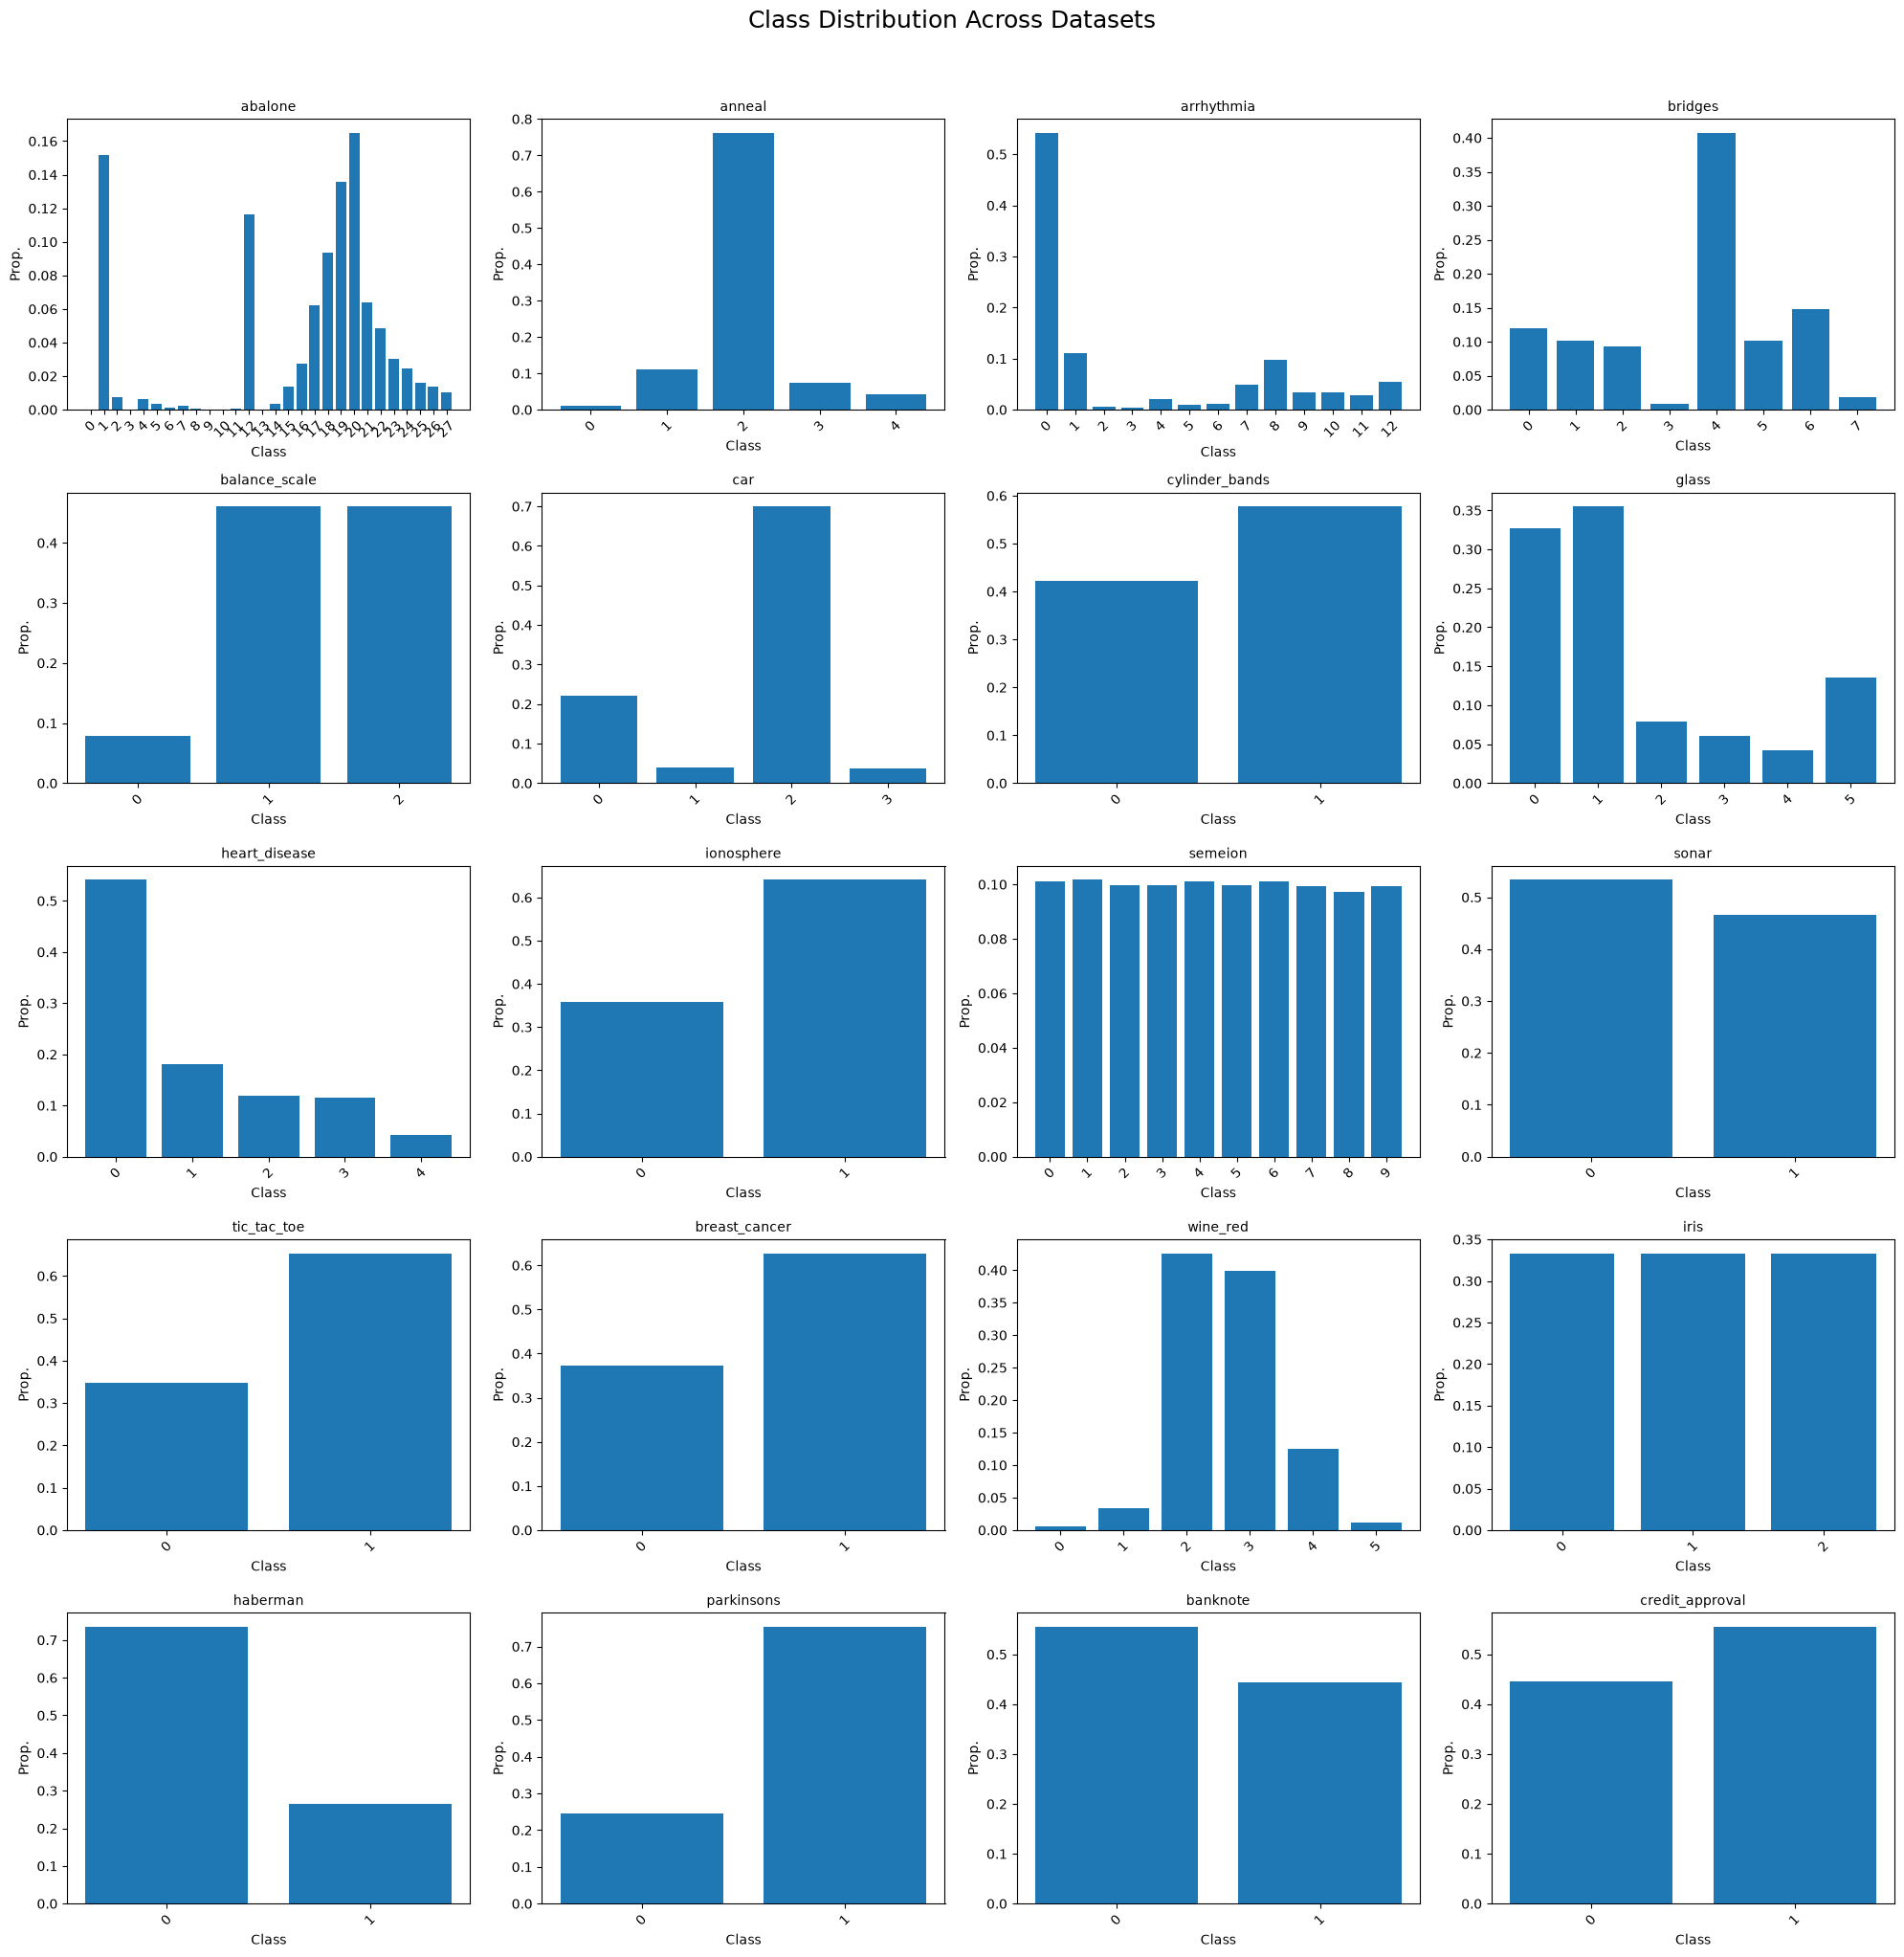

In [6]:
# ==========================================
# 4. CLASS BALANCE PLOTS (ALL TOGETHER)
# ==========================================

datasets_names = list(loaded.keys())

n_datasets = len(datasets_names)

# Grid size
cols = 4
rows = math.ceil(n_datasets / cols)

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))

# Flatten axes for easier iteration
axes = axes.flatten()

for idx, name in enumerate(datasets_names):

    temp = class_distribution_df[
        class_distribution_df["dataset"] == name
    ]

    axes[idx].bar(
        temp["class"].astype(str),
        temp["proportion"]
    )

    axes[idx].set_title(name, fontsize=10)
    axes[idx].set_xlabel("Class")
    axes[idx].set_ylabel("Prop.")

    axes[idx].tick_params(axis='x', rotation=45)

# Remove unused subplots
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Class Distribution Across Datasets",
    fontsize=18,
    y=1.02
)

plt.tight_layout()
plt.show()


**EXPLORATORY / SUPPORTING DESCRIPTORS — never used to assign labels.**

## 5. Missing values analysis

This tells whether missing-value handling genes are likely to matter.

In [7]:
missing_rows = []
for name, obj in loaded.items():
    X = obj["X"]
    missing_by_feature = X.isna().mean().sort_values(ascending=False) * 100
    for feature, pct in missing_by_feature.items():
        if pct > 0:
            missing_rows.append({"dataset": name, "feature": feature, "missing_pct": pct})

missing_df = pd.DataFrame(missing_rows)
missing_df.to_csv(output_dir / "missing_values_by_feature.csv", index=False)
missing_df.head(30)


,dataset,feature,missing_pct
0,anneal,feature_022,100.000000
1,anneal,feature_029,100.000000
2,anneal,feature_030,100.000000
3,anneal,feature_025,100.000000
4,anneal,feature_028,100.000000
5,anneal,feature_018,100.000000
6,anneal,feature_013,99.874687
7,anneal,feature_023,99.749373
8,anneal,feature_026,99.373434
9,anneal,feature_020,99.122807


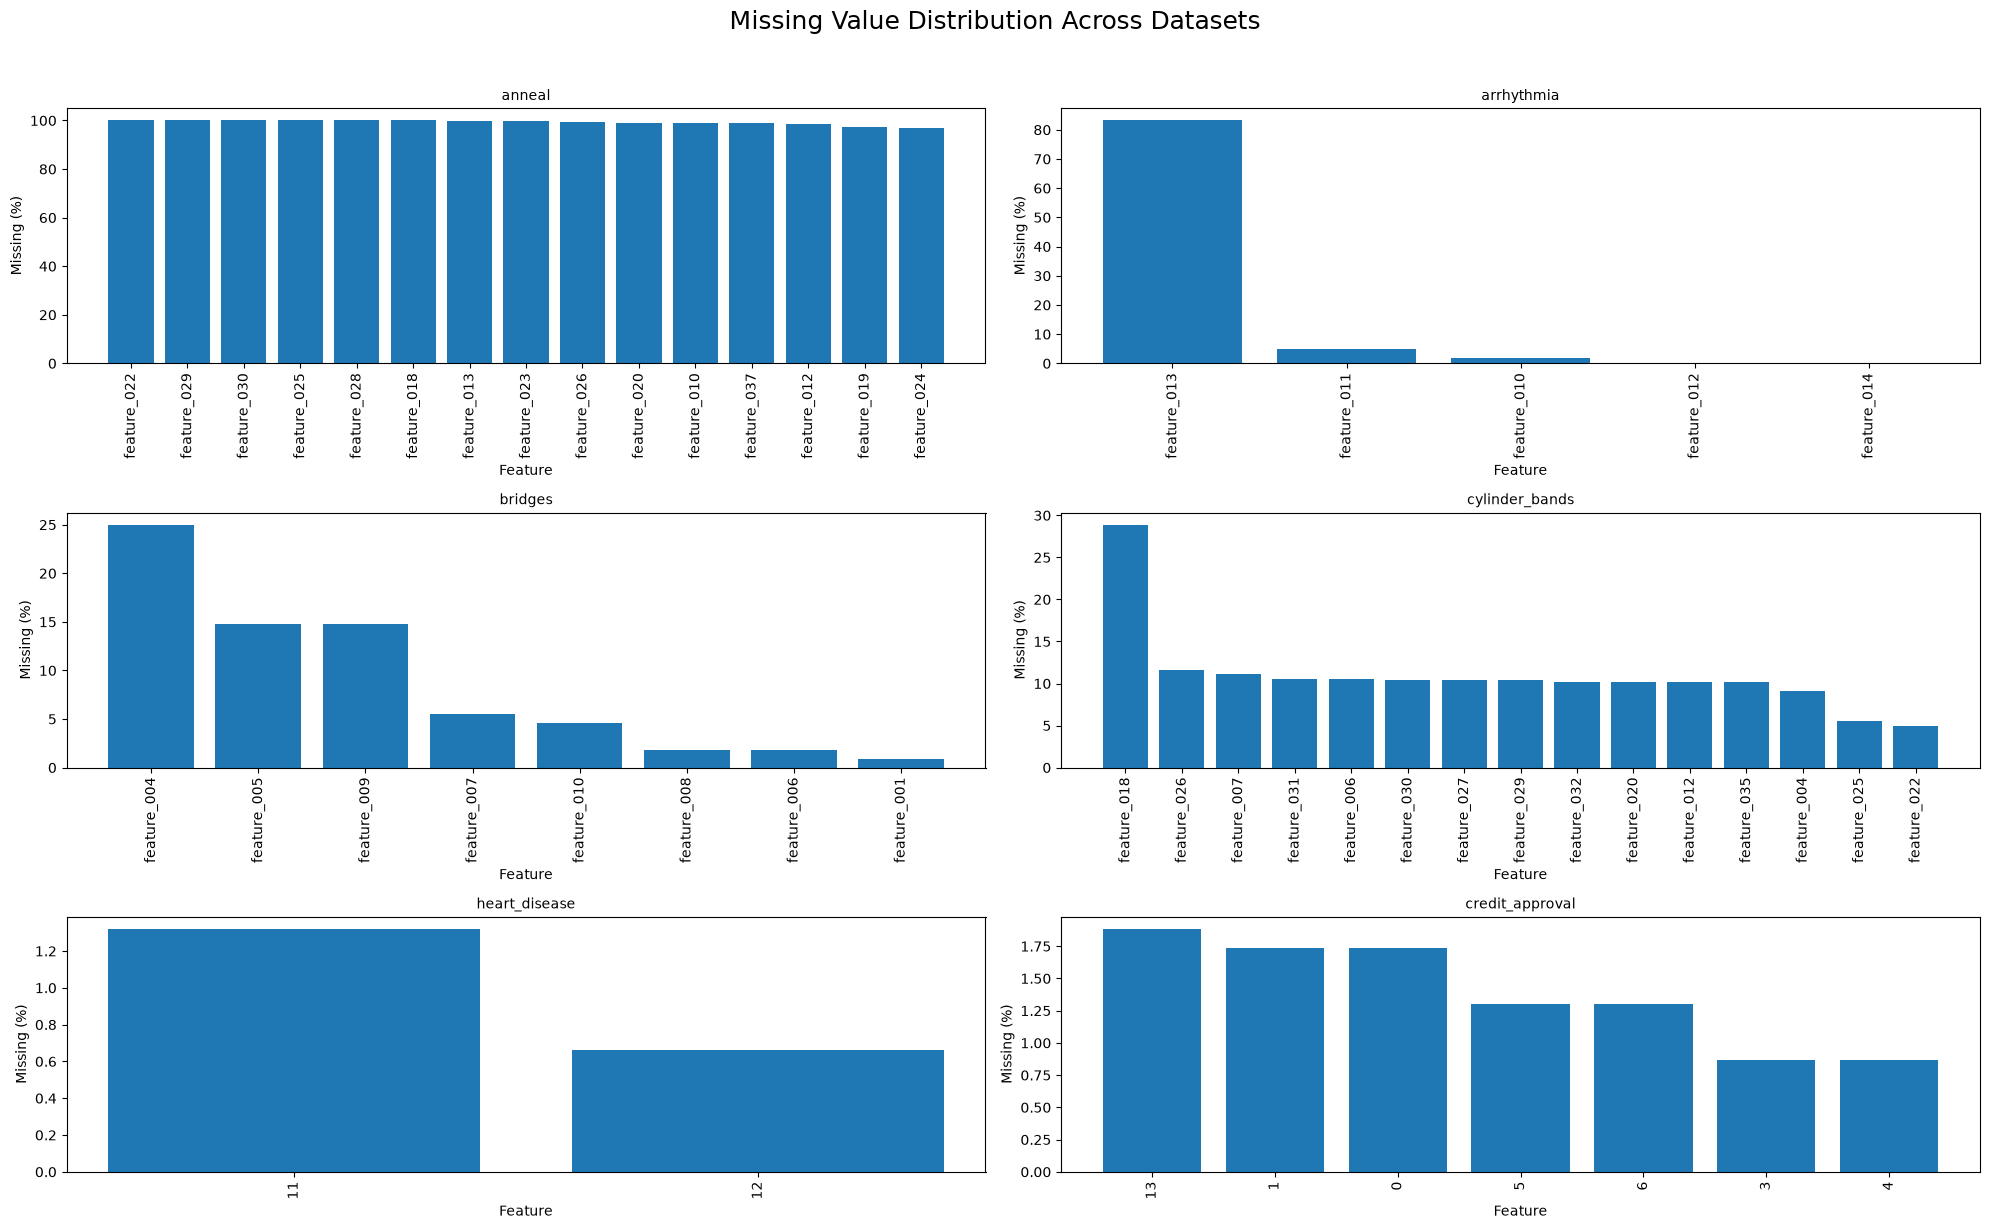

In [8]:
# ==========================================
# MISSING VALUE ANALYSIS (ALL TOGETHER)
# ==========================================
import math
if not missing_df.empty:

    datasets_with_missing = missing_df["dataset"].unique()

    n_datasets = len(datasets_with_missing)

    cols = 2
    rows = math.ceil(n_datasets / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(20, rows * 4)
    )

    axes = axes.flatten()

    for idx, name in enumerate(datasets_with_missing):

        temp = missing_df[
            missing_df["dataset"] == name
        ].head(15)

        axes[idx].bar(
            temp["feature"].astype(str),
            temp["missing_pct"]
        )

        axes[idx].set_title(name, fontsize=10)
        axes[idx].set_xlabel("Feature")
        axes[idx].set_ylabel("Missing (%)")

        axes[idx].tick_params(
            axis='x',
            rotation=90
        )

    # Remove empty subplots
    for j in range(idx + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle(
        "Missing Value Distribution Across Datasets",
        fontsize=18,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

**EXPLORATORY / SUPPORTING DESCRIPTORS — never used to assign labels.**

## 6. Numeric descriptive statistics

Mean, median, standard deviation, skewness, kurtosis, and unique values.

In [9]:
descriptive_rows = []
for name, obj in loaded.items():
    numeric_X = obj["X"].select_dtypes(include=[np.number])
    for feature in numeric_X.columns:
        s = numeric_X[feature].dropna()
        if len(s) == 0:
            continue
        descriptive_rows.append({
            "dataset": name,
            "feature": feature,
            "mean": s.mean(),
            "median": s.median(),
            "std": s.std(),
            "min": s.min(),
            "max": s.max(),
            "skewness": skew(s),
            "kurtosis": kurtosis(s),
            "n_unique": s.nunique(),
        })

descriptive_df = pd.DataFrame(descriptive_rows)
descriptive_df.to_csv(output_dir / "numeric_descriptive_statistics.csv", index=False)
descriptive_df.head(20)


,dataset,feature,mean,median,std,min,max,skewness,kurtosis,n_unique
0,abalone,feature_001,0.523992,0.5450,0.120093,0.0750,0.8150,-0.639643,0.063108,134
1,abalone,feature_002,0.407881,0.4250,0.099240,0.0550,0.6500,-0.608979,-0.046857,111
2,abalone,feature_003,0.139516,0.1400,0.041827,0.0000,1.1300,3.127694,75.933099,51
3,abalone,feature_004,0.828742,0.7995,0.490389,0.0020,2.8255,0.530768,-0.025051,2429
4,abalone,feature_005,0.359367,0.3360,0.221963,0.0010,1.4880,0.718840,0.592975,1515
5,abalone,feature_006,0.180594,0.1710,0.109614,0.0005,0.7600,0.591640,0.082475,880
6,abalone,feature_007,0.238831,0.2340,0.139203,0.0015,1.0050,0.620704,0.529854,926
7,anneal,feature_003,3.547619,0.0000,13.592644,0.0000,70.0000,3.815705,13.020051,10
8,anneal,feature_004,11.748120,0.0000,24.621001,0.0000,85.0000,1.821492,1.835243,7
9,anneal,feature_007,2.223301,2.0000,0.659148,1.0000,5.0000,1.194513,3.939406,4


**EXPLORATORY / SUPPORTING DESCRIPTORS — never used to assign labels.**

## 7. Low-variance features

Low-variance features may provide little information for splits.

In [10]:
low_variance_rows = []
for name, obj in loaded.items():
    numeric_X = obj["X"].select_dtypes(include=[np.number])
    for feature in numeric_X.columns:
        s = numeric_X[feature].dropna()
        if len(s) == 0:
            continue
        low_variance_rows.append({
            "dataset": name,
            "feature": feature,
            "variance": s.var(),
            "n_unique": s.nunique(),
        })

low_variance_df = pd.DataFrame(low_variance_rows).sort_values(["dataset", "variance"])
low_variance_df.to_csv(output_dir / "low_variance_features.csv", index=False)
low_variance_df.head(30)


,dataset,feature,variance,n_unique
2,abalone,feature_003,1.749503e-03,51
1,abalone,feature_002,9.848551e-03,111
5,abalone,feature_006,1.201528e-02,880
0,abalone,feature_001,1.442231e-02,134
6,abalone,feature_007,1.937738e-02,926
4,abalone,feature_005,4.926755e-02,1515
3,abalone,feature_004,2.404814e-01,2429
16,anneal,feature_037,1.111111e-01,2
11,anneal,feature_012,2.564103e-01,2
9,anneal,feature_007,4.344755e-01,4


**EXPLORATORY / SUPPORTING DESCRIPTORS — never used to assign labels.**

## 8. Outlier analysis

Outliers are estimated using IQR and z-score. They can affect threshold-based splits.

In [11]:
outlier_rows = []
for name, obj in loaded.items():
    numeric_X = obj["X"].select_dtypes(include=[np.number])
    for feature in numeric_X.columns:
        s = numeric_X[feature].dropna()
        if len(s) < 3:
            continue
        q1, q3 = np.percentile(s, [25, 75])
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        iqr_outliers = ((s < lower) | (s > upper)).mean() * 100
        z_outliers = (np.abs(zscore(s)) > 3).mean() * 100
        outlier_rows.append({
            "dataset": name,
            "feature": feature,
            "iqr_outlier_pct": iqr_outliers,
            "zscore_outlier_pct": z_outliers,
        })

outlier_df = pd.DataFrame(outlier_rows)
outlier_df.to_csv(output_dir / "outlier_analysis.csv", index=False)
outlier_df.sort_values(["dataset", "iqr_outlier_pct"], ascending=[True, False]).head(30)


,dataset,feature,iqr_outlier_pct,zscore_outlier_pct
1,abalone,feature_002,1.412497,0.311228
0,abalone,feature_001,1.173091,0.359109
4,abalone,feature_005,1.149150,0.885803
6,abalone,feature_007,0.837922,0.646397
3,abalone,feature_004,0.718219,0.454872
2,abalone,feature_003,0.694278,0.119703
5,abalone,feature_006,0.622456,0.526694
14,anneal,feature_034,22.431078,0.000000
8,anneal,feature_004,19.799499,0.000000
16,anneal,feature_037,11.111111,0.000000


**EXPLORATORY / SUPPORTING DESCRIPTORS — never used to assign labels.**

## 9. Feature-class separability tests

For numeric features:

- ANOVA checks whether mean values differ across classes.
- Kruskal-Wallis is a non-parametric alternative.

Small p-values suggest that the feature may help separate classes.

In [12]:
separability_rows = []
for name, obj in loaded.items():
    X, y = obj["X"], obj["y"]
    numeric_X = X.select_dtypes(include=[np.number])
    classes = np.unique(y)
    for feature in numeric_X.columns:
        groups = []
        for cls in classes:
            values = numeric_X.loc[y == cls, feature].dropna().values
            if len(values) > 1:
                groups.append(values)
        if len(groups) < 2:
            continue
        try:
            anova_stat, anova_p = f_oneway(*groups)
        except Exception:
            anova_stat, anova_p = np.nan, np.nan
        try:
            kruskal_stat, kruskal_p = kruskal(*groups)
        except Exception:
            kruskal_stat, kruskal_p = np.nan, np.nan
        separability_rows.append({
            "dataset": name,
            "feature": feature,
            "anova_p": anova_p,
            "kruskal_p": kruskal_p,
            "anova_stat": anova_stat,
            "kruskal_stat": kruskal_stat,
        })

separability_df = pd.DataFrame(separability_rows)
separability_df.to_csv(output_dir / "feature_class_separability_tests.csv", index=False)
separability_df.sort_values(["dataset", "kruskal_p"]).head(30)


C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\.venv\Lib\site-packages\scipy\stats\_stats_py.py:8674: RuntimeWarning: invalid value encountered in scalar divide
  h /= ties


,dataset,feature,anova_p,kruskal_p,anova_stat,kruskal_stat
0,abalone,feature_001,0.000000e+00,0.000000e+00,228.612857,1883.888382
1,abalone,feature_002,0.000000e+00,0.000000e+00,238.311683,1941.808839
2,abalone,feature_003,0.000000e+00,0.000000e+00,150.803817,2009.722020
3,abalone,feature_004,0.000000e+00,0.000000e+00,138.677333,1945.096267
4,abalone,feature_005,0.000000e+00,0.000000e+00,98.630296,1650.491201
5,abalone,feature_006,0.000000e+00,0.000000e+00,126.753934,1894.927766
6,abalone,feature_007,0.000000e+00,0.000000e+00,179.518538,2191.917129
8,anneal,feature_004,3.265697e-78,2.691340e-43,116.605005,205.324516
10,anneal,feature_008,2.641122e-26,1.498158e-22,34.127283,108.529543
12,anneal,feature_032,4.937191e-05,9.863091e-10,6.351938,47.908178


**EXPLORATORY / SUPPORTING DESCRIPTORS — never used to assign labels.**

## 10. Correlation analysis

Highly correlated numeric features may indicate redundancy.

In [13]:
correlation_rows = []
for name, obj in loaded.items():
    numeric_X = obj["X"].select_dtypes(include=[np.number])
    if numeric_X.shape[1] < 2:
        continue
    corr = numeric_X.corr(method="spearman").abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    high_pairs = upper.stack().reset_index()
    high_pairs.columns = ["feature_1", "feature_2", "abs_spearman_corr"]
    high_pairs = high_pairs.sort_values("abs_spearman_corr", ascending=False)
    for _, row in high_pairs.head(20).iterrows():
        correlation_rows.append({
            "dataset": name,
            "feature_1": row["feature_1"],
            "feature_2": row["feature_2"],
            "abs_spearman_corr": row["abs_spearman_corr"],
        })

correlation_df = pd.DataFrame(correlation_rows)
correlation_df.to_csv(output_dir / "top_feature_correlations.csv", index=False)
correlation_df.head(30)


,dataset,feature_1,feature_2,abs_spearman_corr
0,abalone,feature_001,feature_002,0.983319
1,abalone,feature_004,feature_005,0.977060
2,abalone,feature_004,feature_006,0.975252
3,abalone,feature_001,feature_004,0.972633
4,abalone,feature_002,feature_004,0.971324
5,abalone,feature_004,feature_007,0.969426
6,abalone,feature_001,feature_005,0.956830
7,abalone,feature_002,feature_007,0.954149
8,abalone,feature_001,feature_006,0.952658
9,abalone,feature_002,feature_005,0.950472


**EXPLORATORY / SUPPORTING DESCRIPTORS — never used to assign labels.**

## 11. Univariate feature importance

Mutual Information and Chi-square scores estimate individual predictive signal per feature.

In [14]:
def make_encoded_matrix(X):
    X_copy = X.copy()
    numeric_cols = X_copy.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in X_copy.columns if c not in numeric_cols]
    parts = []
    feature_names = []

    if numeric_cols:
        X_num = Pipeline([("imputer", SimpleImputer(strategy="median"))]).fit_transform(X_copy[numeric_cols])
        parts.append(X_num)
        feature_names.extend(numeric_cols)

    if categorical_cols:
        X_cat = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ]).fit_transform(X_copy[categorical_cols].astype(str))
        parts.append(X_cat)
        feature_names.extend(categorical_cols)

    if not parts:
        return None, []
    return np.hstack(parts), feature_names

importance_rows = []
for name, obj in loaded.items():
    X, y = obj["X"], obj["y"]
    X_encoded, feature_names = make_encoded_matrix(X)
    if X_encoded is None:
        continue
    try:
        mi = mutual_info_classif(X_encoded, y, random_state=42)
    except Exception:
        mi = np.full(X_encoded.shape[1], np.nan)
    try:
        X_nonnegative = MinMaxScaler().fit_transform(X_encoded)
        chi_scores, chi_p = chi2(X_nonnegative, y)
    except Exception:
        chi_scores = np.full(X_encoded.shape[1], np.nan)
        chi_p = np.full(X_encoded.shape[1], np.nan)
    for feature, mi_score, chi_score, p_val in zip(feature_names, mi, chi_scores, chi_p):
        importance_rows.append({
            "dataset": name,
            "feature": feature,
            "mutual_information": mi_score,
            "chi2_score": chi_score,
            "chi2_p": p_val,
        })

importance_df = pd.DataFrame(importance_rows)
importance_df.to_csv(output_dir / "univariate_feature_importance.csv", index=False)
importance_df.sort_values(["dataset", "mutual_information"], ascending=[True, False]).head(30)


C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['feature_018' 'feature_022' 'feature_025' 'feature_028' 'feature_029'
 'feature_030']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


,dataset,feature,mutual_information,chi2_score,chi2_p
6,abalone,feature_007,0.464273,166.254507,5.391010e-22
1,abalone,feature_002,0.406307,109.903884,5.762068e-12
3,abalone,feature_004,0.390034,182.963465,4.135206e-25
2,abalone,feature_003,0.375622,20.734631,7.985581e-01
5,abalone,feature_006,0.374857,147.825210,1.273761e-18
0,abalone,feature_001,0.371289,99.863833,2.709953e-10
4,abalone,feature_005,0.329069,133.046654,5.648614e-16
7,abalone,feature_000,0.162174,5.127324,9.999987e-01
13,anneal,feature_018,0.330094,5.256515,2.619753e-01
9,anneal,feature_004,0.177926,179.179787,1.118622e-37


## 12. Baseline performance and dataset difficulty dimensions

Baselines use macro-F1 under the same repeated stratified 5-fold protocol.

The dataset characterization is explicitly separated into three dimensions:

1. **Predictive difficulty**: low baseline macro-F1 plus high within-model CV instability.
2. **Strategy sensitivity**: disagreement between baseline algorithms.
3. **Computational burden**: runtime and tree-size/complexity indicators.

The primary Easy/Intermediate/Hard label is based only on predictive difficulty. Model spread, tree size, and runtime remain available as complementary experimental-profile descriptors, and never enter the main difficulty category.


In [15]:
def build_preprocessor(X, for_linear=False):
    numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if for_linear:
        numeric_steps.append(("scaler", StandardScaler()))

    # Use sparse_output when available; fall back for older scikit-learn.
    try:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

    transformers = []
    if numeric_cols:
        transformers.append(("num", Pipeline(numeric_steps), numeric_cols))
    if categorical_cols:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", onehot),
            ]),
            categorical_cols,
        ))

    return ColumnTransformer(transformers, remainder="drop")


# PAPER-DEFINED common protocol. Runtime = elapsed seconds for all 15 CV fits
# and scores for a strategy (including pipeline and scheduling overhead).
CV_N_SPLITS, CV_N_REPEATS, CV_RANDOM_STATE = 5, 3, 42
N_JOBS = 1  # serial execution makes warning capture and timing auditable
NON_DUMMY_BASELINE_MODELS = ['decision_tree_default', 'decision_tree_balanced',
                            'logistic_regression', 'logistic_regression_balanced']
TREE_BASELINE_MODELS = NON_DUMMY_BASELINE_MODELS[:2]
DUMMY_REFERENCE_MODELS = ['dummy_most_frequent', 'dummy_stratified']
TREE_CONFIG = dict(criterion='gini', splitter='best', max_depth=None,
                   min_samples_split=2, min_samples_leaf=1, max_features=None,
                   min_weight_fraction_leaf=0.0, max_leaf_nodes=None,
                   min_impurity_decrease=0.0, class_weight=None, ccp_alpha=0.0,
                   random_state=42)
LR_CONFIG = dict(penalty='l2', C=1.0, solver='lbfgs', max_iter=5000,
                 tol=1e-4, class_weight=None, random_state=42, fit_intercept=True)
MODEL_CONFIGS = {
    'decision_tree_default': TREE_CONFIG,
    'decision_tree_balanced': {**TREE_CONFIG, 'class_weight': 'balanced'},
    'logistic_regression': LR_CONFIG,
    'logistic_regression_balanced': {**LR_CONFIG, 'class_weight': 'balanced'},
    'dummy_most_frequent': dict(strategy='most_frequent', random_state=42),
    'dummy_stratified': dict(strategy='stratified', random_state=42),
}
reproducibility = dict(python=platform.python_version(), numpy=np.__version__,
    pandas=pd.__version__, scipy=scipy.__version__, sklearn=sklearn.__version__,
    cv=dict(n_splits=5, n_repeats=3, random_state=42), random_seed=42,
    n_jobs=N_JOBS, model_configurations=MODEL_CONFIGS,
    runtime_definition='wall-clock seconds for complete 15-evaluation cross_validate call')
(output_dir / 'reproducibility.json').write_text(json.dumps(reproducibility, indent=2))
display(pd.DataFrame({'setting': reproducibility.keys(),
                      'value': [str(v) for v in reproducibility.values()]}))

def make_baseline(name, X):
    config = MODEL_CONFIGS[name]
    if name in DUMMY_REFERENCE_MODELS:
        return DummyClassifier(**config)
    linear = name.startswith('logistic')
    estimator = LogisticRegression(**config) if linear else DecisionTreeClassifier(**config)
    return Pipeline([('preprocess', build_preprocessor(X, for_linear=linear)),
                     ('model', estimator)])

def evaluate_baselines(data, cv_seed=42, include_dummy=True):
    from sklearn.model_selection import RepeatedStratifiedKFold
    rows, audits = [], []
    models = NON_DUMMY_BASELINE_MODELS + (DUMMY_REFERENCE_MODELS if include_dummy else [])
    for name, obj in data.items():
        X, y = obj['X'], obj['y']
        minimum = int(np.bincount(y).min())
        eligible = minimum >= CV_N_SPLITS
        issue = '' if eligible else f'min_class_count={minimum} < 5'
        audits.append(dict(dataset=name, min_class_count=minimum, comparable_cv=eligible,
                           cv_issue=issue, cv_n_splits=5, cv_n_repeats=3, cv_seed=cv_seed))
        splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3,
                      random_state=cv_seed).split(X, y)) if eligible else []
        for model_name in models:
            row = dict(dataset=name, model=model_name, cv_seed=cv_seed, cv_folds=5,
                cv_repeats=3, n_scores=0, scores=[], error=issue, warnings='',
                f1_macro_mean=np.nan, f1_macro_std=np.nan, f1_macro_min=np.nan,
                f1_macro_max=np.nan, runtime_seconds=np.nan, mean_tree_nodes=np.nan,
                mean_tree_depth=np.nan, mean_tree_leaves=np.nan)
            caught = []
            if eligible:
                try:
                    start = time.perf_counter()
                    with warnings.catch_warnings(record=True) as caught:
                        warnings.simplefilter('always')
                        result = cross_validate(make_baseline(model_name, X), X, y,
                            cv=splits, scoring=make_scorer(f1_score, average='macro', zero_division=0),
                            n_jobs=N_JOBS, error_score='raise',
                            return_estimator=model_name in TREE_BASELINE_MODELS)
                    scores = result['test_score']
                    assert len(scores) == 15 and np.isfinite(scores).all(), 'Invalid CV scores'
                    row.update(n_scores=len(scores), scores=scores.tolist(),
                        f1_macro_mean=scores.mean(), f1_macro_std=scores.std(ddof=1),
                        f1_macro_min=scores.min(), f1_macro_max=scores.max(),
                        runtime_seconds=time.perf_counter()-start)
                    if model_name in TREE_BASELINE_MODELS:
                        trees = [e.named_steps['model'].tree_ for e in result['estimator']]
                        row.update(mean_tree_nodes=np.mean([t.node_count for t in trees]),
                            mean_tree_depth=np.mean([t.max_depth for t in trees]),
                            mean_tree_leaves=np.mean([t.n_leaves for t in trees]))
                except Exception as exc:
                    row['error'] = repr(exc)
                    print(f'[FIT ERROR] {name}/{model_name}: {exc}')
                row['warnings'] = '\n'.join(sorted({f'{w.category.__name__}: {w.message}' for w in caught}))
                if row['warnings']:
                    print(f'[WARNINGS] {name}/{model_name}: {row["warnings"][:300]}')
            rows.append(row)
        print(f'CV seed {cv_seed}: {name} completed; comparable={eligible}')
    return pd.DataFrame(rows), pd.DataFrame(audits)

def successful_rows(frame):
    return (frame['error'].fillna('').eq('') & frame['n_scores'].eq(15)
            & frame['scores'].map(lambda s: len(s) == 15 and np.isfinite(s).all())
            & frame[['f1_macro_mean', 'f1_macro_std']].notna().all(axis=1))

def aggregate_baselines(frame, audit):
    good = frame.loc[successful_rows(frame) & frame.model.isin(NON_DUMMY_BASELINE_MODELS)]
    agg = good.groupby('dataset').agg(n_successful_non_dummy_models=('model','nunique'),
        baseline_macro_f1_mean=('f1_macro_mean','mean'),
        baseline_macro_f1_best=('f1_macro_mean','max'),
        baseline_macro_f1_worst=('f1_macro_mean','min'),
        mean_model_cv_f1_std=('f1_macro_std','mean')).reset_index()
    agg = audit.merge(agg, on='dataset', how='left', validate='one_to_one')
    complete = frame[frame.model.isin(NON_DUMMY_BASELINE_MODELS)].groupby('dataset').apply(
        lambda g: len(g) == 4 and set(g.model) == set(NON_DUMMY_BASELINE_MODELS)
        and successful_rows(g).all())
    agg['complete_non_dummy_protocol'] = agg.dataset.map(complete).fillna(False).astype(bool)
    agg['ranking_eligible'] = (agg.comparable_cv & agg.min_class_count.ge(5)
        & agg.complete_non_dummy_protocol
        & agg[['baseline_macro_f1_mean','mean_model_cv_f1_std']].notna().all(axis=1))
    agg['ranking_exclusion_reason'] = agg.apply(lambda r: '' if r.ranking_eligible else
        (r.cv_issue or 'Incomplete four-model protocol: inspect baseline_results.csv errors and score counts'), axis=1)
    # Partial models remain in baseline_df for inspection, never canonical aggregates.
    agg.loc[~agg.ranking_eligible, ['baseline_macro_f1_mean','baseline_macro_f1_best',
        'baseline_macro_f1_worst','mean_model_cv_f1_std']] = np.nan
    agg['baseline_macro_f1_spread'] = agg.baseline_macro_f1_best - agg.baseline_macro_f1_worst
    agg['cv_variability'] = agg.mean_model_cv_f1_std
    dummy = frame.loc[successful_rows(frame) & frame.model.isin(DUMMY_REFERENCE_MODELS)]
    agg['best_dummy_macro_f1'] = agg.dataset.map(dummy.groupby('dataset').f1_macro_mean.max())
    agg['baseline_gain_over_dummy'] = agg.baseline_macro_f1_mean - agg.best_dummy_macro_f1
    return agg

baseline_df, cv_audit_df = evaluate_baselines(loaded)
baseline_characteristics_df = aggregate_baselines(baseline_df, cv_audit_df)
display(baseline_characteristics_df)


,setting,value
0,python,3.12.14
1,numpy,2.5.3
2,pandas,3.0.5
3,scipy,1.18.1
4,sklearn,1.9.0
5,cv,"{'n_splits': 5, 'n_repeats': 3, 'random_state'..."
6,random_seed,42
7,n_jobs,1
8,model_configurations,{'decision_tree_default': {'criterion': 'gini'...
9,runtime_definition,wall-clock seconds for complete 15-evaluation ...


CV seed 42: abalone completed; comparable=False


[WARNINGS] anneal/decision_tree_default: UserWarning: Skipping features without any observed values: ['feature_013']. At least one non-missing value is needed for imputation with strategy='most_frequent'.
 'fea


[WARNINGS] anneal/decision_tree_balanced: UserWarning: Skipping features without any observed values: ['feature_013']. At least one non-missing value is needed for imputation with strategy='most_frequent'.
 'fea


[WARNINGS] anneal/logistic_regression: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i


[WARNINGS] anneal/logistic_regression_balanced: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
CV seed 42: anneal completed; comparable=True
CV seed 42: arrhythmia completed; comparable=False
CV seed 42: bridges completed; comparable=False


... (21 outputs left out)

[WARNINGS] banknote/logistic_regression: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
[WARNINGS] banknote/logistic_regression_balanced: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
CV seed 42: banknote completed; comparable=True


[WARNINGS] credit_approval/logistic_regression: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i


[WARNINGS] credit_approval/logistic_regression_balanced: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
CV seed 42: credit_approval completed; comparable=True


,dataset,min_class_count,comparable_cv,cv_issue,cv_n_splits,cv_n_repeats,cv_seed,n_successful_non_dummy_models,baseline_macro_f1_mean,baseline_macro_f1_best,baseline_macro_f1_worst,mean_model_cv_f1_std,complete_non_dummy_protocol,ranking_eligible,ranking_exclusion_reason,baseline_macro_f1_spread,cv_variability,best_dummy_macro_f1,baseline_gain_over_dummy
0,abalone,1,False,min_class_count=1 < 5,5,3,42,NaN,NaN,NaN,NaN,NaN,False,False,min_class_count=1 < 5,NaN,NaN,NaN,NaN
1,anneal,8,True,,5,3,42,4.0,0.787616,0.907593,0.619046,0.068199,True,True,,0.288547,0.068199,0.201713,0.585902
2,arrhythmia,2,False,min_class_count=2 < 5,5,3,42,NaN,NaN,NaN,NaN,NaN,False,False,min_class_count=2 < 5,NaN,NaN,NaN,NaN
3,bridges,1,False,min_class_count=1 < 5,5,3,42,NaN,NaN,NaN,NaN,NaN,False,False,min_class_count=1 < 5,NaN,NaN,NaN,NaN
4,balance_scale,49,True,,5,3,42,4.0,0.655278,0.853269,0.582200,0.022802,True,True,,0.271069,0.022802,0.329519,0.325758
5,car,65,True,,5,3,42,4.0,0.865488,0.934814,0.778573,0.031962,True,True,,0.156241,0.031962,0.245868,0.619621
6,cylinder_bands,228,True,,5,3,42,4.0,0.747089,0.761588,0.737483,0.053867,True,True,,0.024105,0.053867,0.494167,0.252921
7,glass,9,True,,5,3,42,4.0,0.621593,0.656832,0.539585,0.083331,True,True,,0.117247,0.083331,0.114581,0.507012
8,heart_disease,13,True,,5,3,42,4.0,0.301257,0.333069,0.236344,0.058837,True,True,,0.096725,0.058837,0.182116,0.119140
9,ionosphere,126,True,,5,3,42,4.0,0.871318,0.883384,0.862892,0.040580,True,True,,0.020492,0.040580,0.504045,0.367274


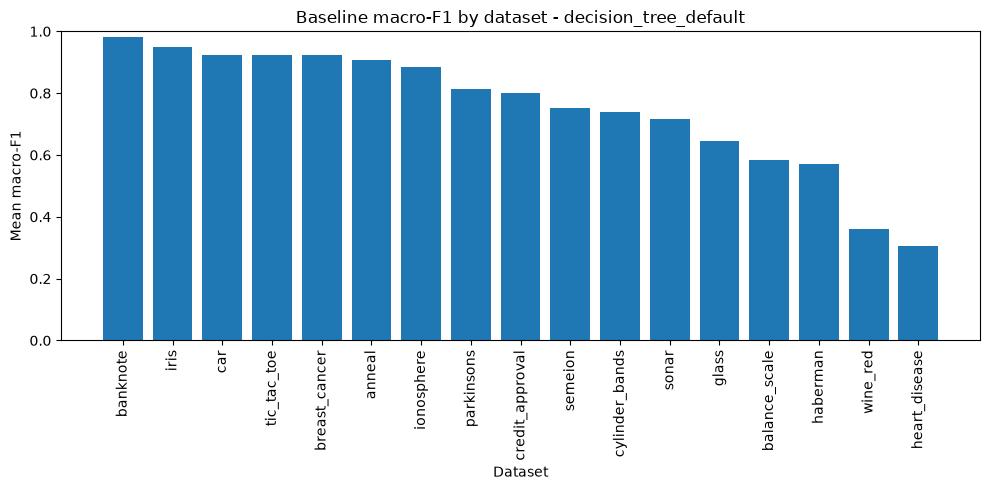

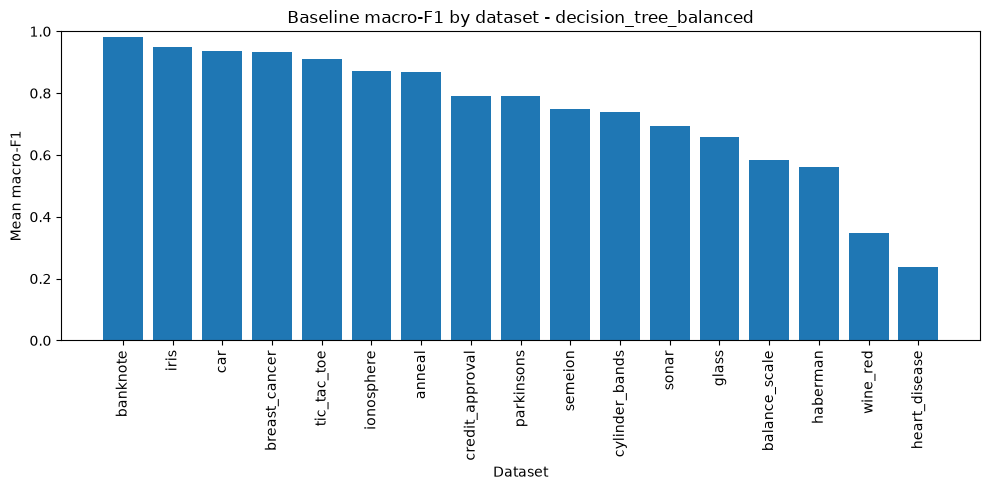

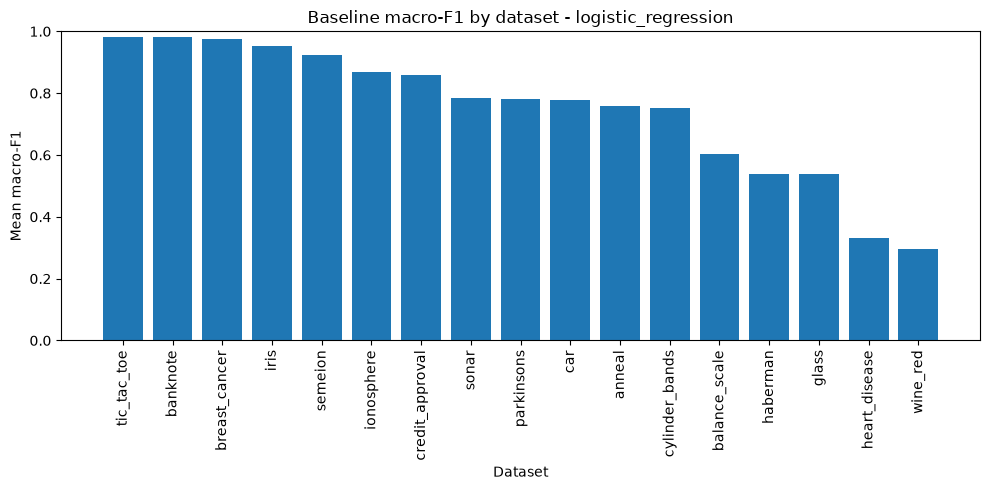

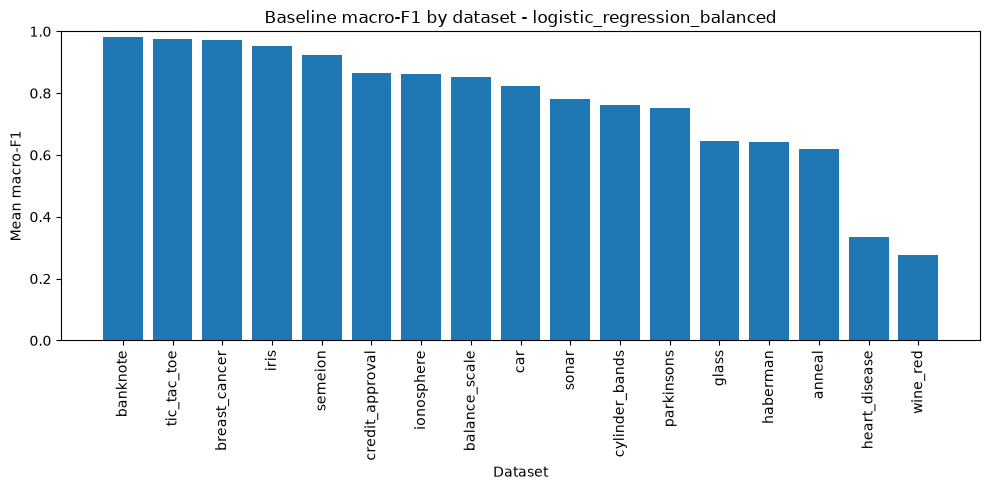

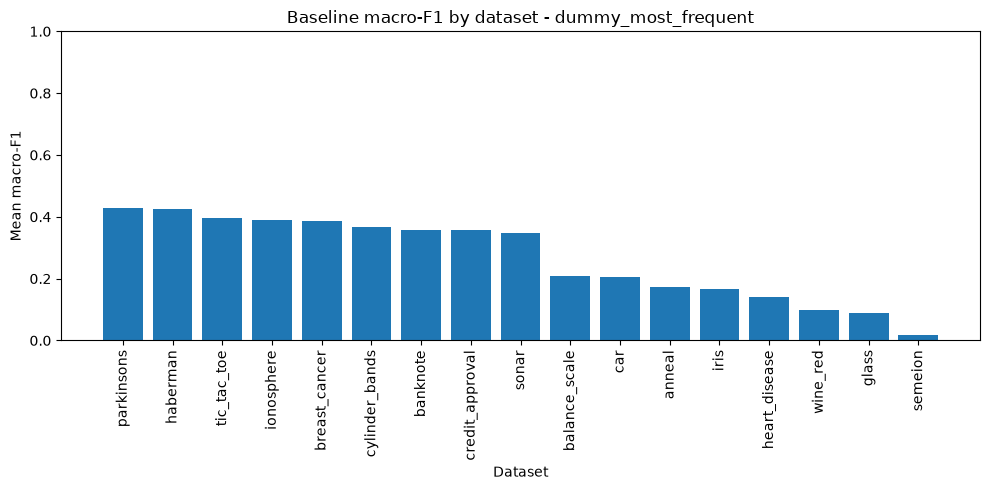

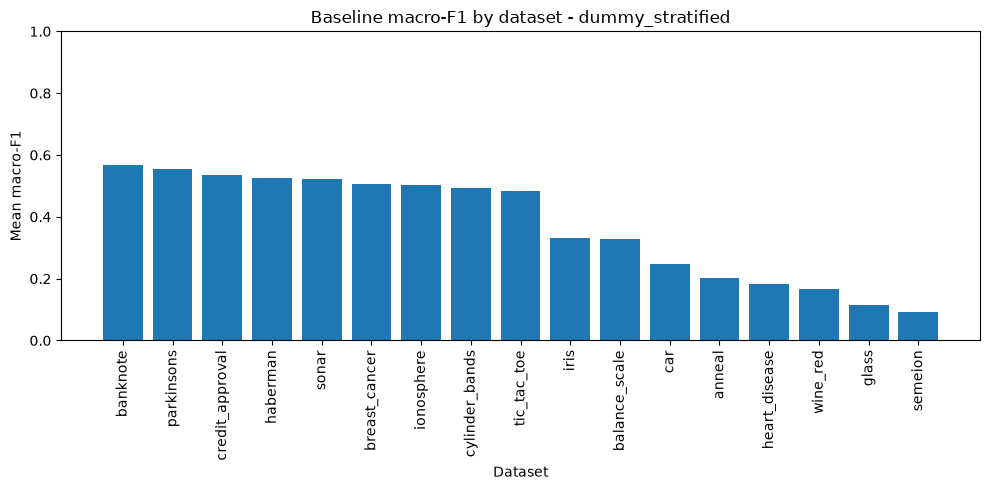

In [16]:
plot_df = baseline_df.dropna(subset=["f1_macro_mean"])
for model_name in plot_df["model"].unique():
    temp = plot_df[plot_df["model"] == model_name].sort_values("f1_macro_mean", ascending=False)
    plt.figure(figsize=(10, 5))
    plt.bar(temp["dataset"], temp["f1_macro_mean"])
    plt.title(f"Baseline macro-F1 by dataset - {model_name}")
    plt.xlabel("Dataset")
    plt.ylabel("Mean macro-F1")
    plt.xticks(rotation=90)
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()


In [17]:
# PAPER-DEFINED computational inputs, calculated once.
computational_source_df = baseline_df.loc[successful_rows(baseline_df)
    & baseline_df.model.isin(NON_DUMMY_BASELINE_MODELS)]
runtime_df = computational_source_df.groupby('dataset').agg(
    baseline_runtime_seconds_mean=('runtime_seconds','mean')).reset_index()
tree_complexity_df = computational_source_df.loc[
    computational_source_df.model.isin(TREE_BASELINE_MODELS)].groupby('dataset').agg(
    mean_tree_nodes=('mean_tree_nodes','mean'), mean_tree_depth=('mean_tree_depth','mean'),
    mean_tree_leaves=('mean_tree_leaves','mean')).reset_index()
computational_characteristics_df = pd.DataFrame({'dataset': list(loaded)}).merge(
    runtime_df, on='dataset', how='left').merge(tree_complexity_df, on='dataset', how='left')
display(computational_characteristics_df)


,dataset,baseline_runtime_seconds_mean,mean_tree_nodes,mean_tree_depth,mean_tree_leaves
0,abalone,NaN,NaN,NaN,NaN
1,anneal,0.433125,130.266667,18.600000,65.633333
2,arrhythmia,NaN,NaN,NaN,NaN
3,bridges,NaN,NaN,NaN,NaN
4,balance_scale,0.109321,262.533333,11.333333,131.766667
5,car,0.221009,211.266667,13.533333,106.133333
6,cylinder_bands,0.305738,126.733333,13.633333,63.866667
7,glass,0.134629,83.666667,10.500000,42.333333
8,heart_disease,0.128953,167.466667,11.833333,84.233333
9,ionosphere,0.139506,44.466667,8.766667,22.733333


In [18]:
# 13. Multi-dimensional dataset profile
# =====================================
# Paper-aligned implementation of Sections 3.3 and 3.4.
#
# Assumptions from upstream cells:
# - baseline_macro_f1_mean = F_d, mean macro-F1 across NON-DUMMY baselines.
# - mean_model_cv_f1_std = V_d, mean within-model CV std across NON-DUMMY baselines.
# - baseline_macro_f1_spread = S_d, range of model-level mean macro-F1 across NON-DUMMY baselines.
# - the target/eligibility audit (min class count >= k=5) was already applied before baseline evaluation.


def minmax_normalize_on_pool(series, pool_mask):
    """Min-max normalize using only the eligible benchmark pool."""
    values = pd.to_numeric(series, errors="coerce")
    pool_mask = pd.Series(pool_mask, index=values.index).fillna(False).astype(bool)

    result = pd.Series(np.nan, index=values.index, dtype=float)
    valid = pool_mask & values.notna()

    if valid.sum() == 0:
        return result

    min_val = values.loc[valid].min()
    max_val = values.loc[valid].max()

    if max_val == min_val:
        result.loc[valid] = 0.0
        return result

    result.loc[valid] = (
        values.loc[valid] - min_val
    ) / (
        max_val - min_val
    )

    return result


# ------------------------------------------------------------------
# Base dataset-level profile
# ------------------------------------------------------------------

dataset_profile_df = baseline_characteristics_df.copy()

# Eligibility was established from all four complete model evaluations.

# ============================================================
# 1. Predictive difficulty
# ============================================================
#
# F_d = mean macro-F1 across non-dummy baseline strategies
# E_d = 1 - F_d
# V_d = mean within-model cross-validation variability
#
# D_pred_d = 0.70 * z(E_d) + 0.30 * z(V_d)


dataset_profile_df["predictive_error"] = (
    1.0 - dataset_profile_df["baseline_macro_f1_mean"]
)

dataset_profile_df["cv_variability"] = (
    dataset_profile_df["mean_model_cv_f1_std"]
)

dataset_profile_df["predictive_error_score"] = minmax_normalize_on_pool(
    dataset_profile_df["predictive_error"],
    dataset_profile_df["ranking_eligible"],
)

dataset_profile_df["cv_variability_score"] = minmax_normalize_on_pool(
    dataset_profile_df["cv_variability"],
    dataset_profile_df["ranking_eligible"],
)

dataset_profile_df["predictive_difficulty_score"] = (
    0.70 * dataset_profile_df["predictive_error_score"]
    + 0.30 * dataset_profile_df["cv_variability_score"]
)


# ============================================================
# 2. Strategy sensitivity
# ============================================================
#
# S_d = max_m(mu_d,m) - min_m(mu_d,m)
#
# This is a complementary descriptor. It does NOT modify the
# Easy / Intermediate / Hard predictive-difficulty label.


dataset_profile_df["strategy_sensitivity"] = (
    dataset_profile_df["baseline_macro_f1_spread"]
)

dataset_profile_df["strategy_sensitivity_score"] = minmax_normalize_on_pool(
    dataset_profile_df["strategy_sensitivity"],
    dataset_profile_df["ranking_eligible"],
)


# ============================================================
# 3. Computational burden
# ============================================================
#
# D_comp_d = [z(T_d) + z(N_d)] / 2
#
# T_d = mean runtime across non-dummy baseline strategies
# N_d = mean node count across decision-tree baselines
#
# Tree depth and leaves are retained for interpretation only.


computational_columns = [
    "baseline_runtime_seconds_mean",
    "mean_tree_nodes",
    "mean_tree_depth",
    "mean_tree_leaves",
    "runtime_burden_score",
    "tree_size_burden_score",
    "computational_burden_score",
]

dataset_profile_df = dataset_profile_df.drop(
    columns=[
        col for col in computational_columns
        if col in dataset_profile_df.columns
    ],
    errors="ignore",
)

dataset_profile_df = dataset_profile_df.merge(
    computational_characteristics_df,
    on="dataset",
    how="left",
)

runtime_col = "baseline_runtime_seconds_mean"
tree_size_col = "mean_tree_nodes"

if runtime_col in dataset_profile_df.columns:
    dataset_profile_df["runtime_burden_score"] = minmax_normalize_on_pool(
        dataset_profile_df[runtime_col],
        dataset_profile_df["ranking_eligible"],
    )
else:
    dataset_profile_df["runtime_burden_score"] = np.nan

if tree_size_col in dataset_profile_df.columns:
    dataset_profile_df["tree_size_burden_score"] = minmax_normalize_on_pool(
        dataset_profile_df[tree_size_col],
        dataset_profile_df["ranking_eligible"],
    )
else:
    dataset_profile_df["tree_size_burden_score"] = np.nan

# Equation (9) requires both normalized components.
dataset_profile_df["computational_burden_score"] = np.nan

complete_comp_mask = (
    dataset_profile_df["runtime_burden_score"].notna()
    & dataset_profile_df["tree_size_burden_score"].notna()
)

dataset_profile_df.loc[
    complete_comp_mask,
    "computational_burden_score",
] = (
    dataset_profile_df.loc[
        complete_comp_mask,
        ["runtime_burden_score", "tree_size_burden_score"],
    ].mean(axis=1)
)


# ============================================================
# 4. Easy / Intermediate / Hard subset construction
# ============================================================
#
# Primary ordering: D_pred ascending.
# Secondary criteria are used only for numerically tied scores:
#   1. higher mean macro-F1 first;
#   2. lower CV variability first.
# Dataset name is only a deterministic final tie-break.
#
# The ordered eligible collection is split into three approximately
# equal-sized groups. Non-eligible datasets remain review_separately.


# Only exactly equal floating-point scores are ties; no near-tie rounding.
SCORE_TIE_ATOL = 0.0

def assign_predictive_difficulty_groups(df):
    labels = pd.Series("review_separately", index=df.index, dtype="object")
    ranks = pd.Series(np.nan, index=df.index, dtype=float)

    valid = (
        df["ranking_eligible"]
        & df["predictive_difficulty_score"].notna()
        & df["baseline_macro_f1_mean"].notna()
        & df["cv_variability"].notna()
    )

    if valid.sum() == 0:
        return labels, ranks

    ranked = df.loc[
        valid,
        [
            "dataset",
            "predictive_difficulty_score",
            "baseline_macro_f1_mean",
            "cv_variability",
        ],
    ].copy()

    # Exact equality implements SCORE_TIE_ATOL = 0 consistently in all analyses.
    ranked["_score_tie_key"] = (
        ranked["predictive_difficulty_score"]
    )

    ranked = ranked.sort_values(
        [
            "_score_tie_key",
            "baseline_macro_f1_mean",
            "cv_variability",
            "dataset",
        ],
        ascending=[True, False, True, True],
        kind="mergesort",
    )

    ranks.loc[ranked.index] = np.arange(1, len(ranked) + 1)

    thirds = np.array_split(ranked.index.to_numpy(), 3)

    for label, indices in zip(
        ["easy", "intermediate", "hard"],
        thirds,
    ):
        labels.loc[indices] = label

    return labels, ranks


(
    dataset_profile_df["predictive_difficulty_label"],
    dataset_profile_df["predictive_difficulty_rank"],
) = assign_predictive_difficulty_groups(dataset_profile_df)


dataset_profile_df["difficulty_label_assignment_note"] = (
    "Relative benchmark-pool strata assigned from "
    "D_pred = 0.70*z(E) + 0.30*z(V). Strategy sensitivity and "
    "computational burden are complementary descriptors and do not "
    "determine the Easy/Intermediate/Hard label."
)


# ============================================================
# 5. Monotonicity audit
# ============================================================
#
# The paper verifies:
# mean(F)_Easy > mean(F)_Intermediate > mean(F)_Hard
#
# Mean is used because predictive error E_d is itself derived from
# mean baseline macro-F1.


ordered_labels = ["easy", "intermediate", "hard"]

predictive_monotonicity_df = (
    dataset_profile_df[
        dataset_profile_df["predictive_difficulty_label"].isin(
            ordered_labels
        )
    ]
    .groupby("predictive_difficulty_label", observed=True)
    .agg(
        n_datasets=("dataset", "nunique"),
        mean_baseline_macro_f1=("baseline_macro_f1_mean", "mean"),
        min_baseline_macro_f1=("baseline_macro_f1_mean", "min"),
        max_baseline_macro_f1=("baseline_macro_f1_mean", "max"),
        mean_cv_variability=("cv_variability", "mean"),
        mean_strategy_sensitivity=("strategy_sensitivity", "mean"),
        mean_computational_burden=("computational_burden_score", "mean"),
    )
    .reindex(ordered_labels)
    .reset_index()
)

group_means = (
    predictive_monotonicity_df
    .set_index("predictive_difficulty_label")["mean_baseline_macro_f1"]
)

is_monotonic_f1 = (
    group_means.notna().all()
    and group_means["easy"] > group_means["intermediate"]
    and group_means["intermediate"] > group_means["hard"]
)

print(
    "Monotonic predictive difficulty "
    "(Easy > Intermediate > Hard):",
    bool(is_monotonic_f1),
)


# ============================================================
# 6. Export and display
# ============================================================


dataset_profile_df.to_csv(
    output_dir / "dataset_experimental_profile.csv",
    index=False,
)

predictive_monotonicity_df.to_csv(
    output_dir / "predictive_difficulty_monotonicity_check.csv",
    index=False,
)


display(predictive_monotonicity_df)

ranking_columns = [
    "dataset",
    "baseline_macro_f1_mean",       # F_d
    "predictive_error_score",       # z(E_d)
    "cv_variability_score",         # z(V_d)
    "predictive_difficulty_score",  # D_pred_d
    "predictive_difficulty_rank",
    "predictive_difficulty_label",
    "strategy_sensitivity",         # S_d
    "strategy_sensitivity_score",
]

for optional_col in [
    "baseline_runtime_seconds_mean",
    "mean_tree_nodes",
    "mean_tree_depth",
    "mean_tree_leaves",
    "computational_burden_score",
]:
    if optional_col in dataset_profile_df.columns:
        ranking_columns.append(optional_col)


display(
    dataset_profile_df[ranking_columns]
    .sort_values(
        ["predictive_difficulty_rank", "dataset"],
        na_position="last",
    )
)


Monotonic predictive difficulty (Easy > Intermediate > Hard): True


,predictive_difficulty_label,n_datasets,mean_baseline_macro_f1,min_baseline_macro_f1,max_baseline_macro_f1,mean_cv_variability,mean_strategy_sensitivity,mean_computational_burden
0,easy,6,0.921886,0.836132,0.981649,0.021646,0.076387,0.208704
1,intermediate,6,0.778932,0.655278,0.871318,0.048132,0.123192,0.172847
2,hard,5,0.513034,0.301257,0.744293,0.060208,0.098343,0.189923


,dataset,baseline_macro_f1_mean,predictive_error_score,cv_variability_score,predictive_difficulty_score,predictive_difficulty_rank,predictive_difficulty_label,strategy_sensitivity,strategy_sensitivity_score,baseline_runtime_seconds_mean,mean_tree_nodes,mean_tree_depth,mean_tree_leaves,computational_burden_score
18,banknote,0.981649,0.000000,0.000000,0.000000,1.0,easy,0.001419,0.000000,0.112527,54.533333,7.500000,27.766667,0.035555
12,tic_tac_toe,0.947288,0.050501,0.111691,0.068858,2.0,easy,0.071098,0.242677,0.167280,138.466667,10.933333,69.733333,0.138032
13,breast_cancer,0.949823,0.046775,0.160305,0.080834,3.0,easy,0.051007,0.172705,0.136857,37.266667,6.800000,19.133333,0.042196
15,iris,0.950938,0.045137,0.439209,0.163358,4.0,easy,0.004489,0.010694,0.106644,14.600000,4.866667,7.800000,0.002506
10,semeion,0.836132,0.213872,0.114398,0.184030,5.0,easy,0.174067,0.601293,0.745405,438.466667,15.166667,219.733333,0.802158
5,car,0.865488,0.170726,0.327237,0.217679,6.0,easy,0.156241,0.539208,0.221009,211.266667,13.533333,106.133333,0.231775
9,ionosphere,0.871318,0.162157,0.440112,0.245544,7.0,intermediate,0.020492,0.066427,0.139506,44.466667,8.766667,22.733333,0.049391
19,credit_approval,0.828486,0.225109,0.368439,0.268108,8.0,intermediate,0.073011,0.249337,0.241052,153.800000,12.766667,77.400000,0.206419
4,balance_scale,0.655278,0.479681,0.207279,0.397961,9.0,intermediate,0.271069,0.939129,0.109321,262.533333,11.333333,131.766667,0.181333
6,cylinder_bands,0.747089,0.344743,0.614119,0.425555,10.0,intermediate,0.024105,0.079012,0.305738,126.733333,13.633333,63.866667,0.237504


## Paper-defined validation after fixed subset assignment
The dataset is the unit of analysis. Tree medians are the primary validation;
logistic regression is complementary. These checks describe the same baselines
used to construct the strata and are internal validation, not independent evidence.
Variability and sensitivity need not be monotonic and never reclassify datasets.

In [19]:
canonical_snapshot_df = dataset_profile_df.copy(deep=True)
def distribution_summary(values):
    values = pd.Series(values).dropna()
    q1, q3 = values.quantile([.25,.75])
    return dict(n_datasets=len(values), median=values.median(), Q1=q1, Q3=q3, IQR=q3-q1)

validation_source = baseline_df.loc[successful_rows(baseline_df)
    & baseline_df.model.isin(NON_DUMMY_BASELINE_MODELS)].merge(
    dataset_profile_df[['dataset','ranking_eligible','predictive_difficulty_label']],
    on='dataset', validate='many_to_one')
validation_source = validation_source.loc[validation_source.ranking_eligible]
validation_rows = []
for model in NON_DUMMY_BASELINE_MODELS:
    for subset in ordered_labels:
        values = validation_source.loc[(validation_source.model == model)
            & (validation_source.predictive_difficulty_label == subset), 'f1_macro_mean']
        validation_rows.append(dict(model=model, subset=subset, **distribution_summary(values)))
subset_predictive_validation_df = pd.DataFrame(validation_rows)
tree_validation_rows=[]
for model in NON_DUMMY_BASELINE_MODELS:
    medians = subset_predictive_validation_df.query('model == @model').set_index('subset')['median']
    tree_validation_rows.append(dict(model=model, primary_tree_validation=model in TREE_BASELINE_MODELS,
        median_ordering_pass=bool(medians['easy'] > medians['intermediate'] > medians['hard'])))
subset_median_ordering_df = pd.DataFrame(tree_validation_rows)
subset_predictive_validation_df.to_csv(output_dir / 'subset_predictive_validation.csv', index=False)
subset_median_ordering_df.to_csv(output_dir / 'subset_median_ordering.csv', index=False)
display(subset_predictive_validation_df)
display(subset_median_ordering_df)

descriptive_rows=[]
for subset in ordered_labels:
    group=dataset_profile_df.loc[dataset_profile_df.predictive_difficulty_label.eq(subset)]
    for metric in ['baseline_macro_f1_mean','cv_variability','strategy_sensitivity',
                   'baseline_runtime_seconds_mean','mean_tree_nodes']:
        descriptive_rows.append(dict(subset=subset, metric=metric, **distribution_summary(group[metric])))
subset_descriptive_statistics_df=pd.DataFrame(descriptive_rows)
subset_descriptive_statistics_df.to_csv(output_dir / 'subset_descriptive_statistics.csv', index=False)
stability_sensitivity_profiles_df=subset_descriptive_statistics_df.loc[
    subset_descriptive_statistics_df.metric.isin(['cv_variability','strategy_sensitivity'])].copy()
stability_sensitivity_profiles_df.to_csv(output_dir / 'subset_stability_sensitivity_profiles.csv', index=False)
display(subset_descriptive_statistics_df)

,model,subset,n_datasets,median,Q1,Q3,IQR
0,decision_tree_default,easy,6,0.923719,0.923127,0.942510,0.019382
1,decision_tree_default,intermediate,6,0.806308,0.753858,0.865912,0.112054
2,decision_tree_default,hard,5,0.569466,0.359384,0.645485,0.286101
3,decision_tree_balanced,easy,6,0.933300,0.915601,0.945223,0.029623
4,decision_tree_balanced,intermediate,6,0.790656,0.750439,0.848191,0.097752
5,decision_tree_balanced,hard,5,0.561017,0.348558,0.656832,0.308274
6,logistic_regression,easy,6,0.963600,0.929865,0.979162,0.049297
7,logistic_regression,intermediate,6,0.768878,0.752110,0.838564,0.086454
8,logistic_regression,hard,5,0.539585,0.330564,0.540064,0.209499
9,logistic_regression_balanced,easy,6,0.961832,0.930338,0.973242,0.042904


,model,primary_tree_validation,median_ordering_pass
0,decision_tree_default,True,True
1,decision_tree_balanced,True,True
2,logistic_regression,False,True
3,logistic_regression_balanced,False,True


,subset,metric,n_datasets,median,Q1,Q3,IQR
0,easy,baseline_macro_f1_mean,6,0.948556,0.885938,0.950659,0.064721
1,easy,cv_variability,6,0.017463,0.015555,0.028775,0.013220
2,easy,strategy_sensitivity,6,0.061053,0.016119,0.134955,0.118836
3,easy,baseline_runtime_seconds_mean,6,0.152069,0.118609,0.207577,0.088968
4,easy,mean_tree_nodes,6,96.500000,41.583333,193.066667,151.483333
5,intermediate,baseline_macro_f1_mean,6,0.785711,0.756268,0.818268,0.062000
6,intermediate,cv_variability,6,0.047224,0.036476,0.064616,0.028140
7,intermediate,strategy_sensitivity,6,0.067468,0.033561,0.221554,0.187994
8,intermediate,baseline_runtime_seconds_mean,6,0.190279,0.126360,0.289566,0.163206
9,intermediate,mean_tree_nodes,6,128.500000,65.033333,147.916667,82.883333


## Supporting dataset-level Spearman and feature separability
These exploratory associations do not affect labels. Each correlation uses one
row per eligible dataset, with pairwise finite observations. P-values are unadjusted;
multiple testing and the small benchmark pool preclude confirmatory interpretation.
Separability proportions use valid p-values for each test as their denominator;
the counts of attempted and valid tests are exported separately.

In [20]:
association_source=dataset_profile_df.merge(summary_df, on='dataset', validate='one_to_one')
association_source=association_source.loc[association_source.ranking_eligible]
correlation_rows_dataset=[]
for indicator in ['predictive_difficulty_score','predictive_error_score','cv_variability_score',
                  'strategy_sensitivity_score','computational_burden_score']:
    for property_name in ['n_features','samples_per_feature','missing_pct','class_entropy',
                          'imbalance_ratio','n_samples','n_classes']:
        pair=association_source[[indicator,property_name]].replace([np.inf,-np.inf],np.nan).dropna()
        valid=len(pair)>=3 and pair.nunique().min()>1
        rho,pvalue=spearmanr(pair[indicator],pair[property_name]) if valid else (np.nan,np.nan)
        correlation_rows_dataset.append(dict(indicator=indicator, property=property_name,
            rho=rho, p_value=pvalue, n_datasets=len(pair), status='ok' if valid else 'insufficient or constant'))
dataset_level_spearman_df=pd.DataFrame(correlation_rows_dataset)
dataset_level_spearman_df.to_csv(output_dir / 'dataset_level_spearman_correlations.csv',index=False)
separability_summary_rows=[]
for name in loaded:
    tests=separability_df.loc[separability_df.dataset.eq(name)]
    row=dict(dataset=name,n_numeric_features_tested=len(tests))
    for test in ['anova','kruskal']:
        pvalues=tests[test+'_p'].dropna()
        row['n_valid_'+test+'_tests']=len(pvalues)
        row['proportion_'+test+'_p_lt_0_05']=(pvalues<.05).mean() if len(pvalues) else np.nan
    separability_summary_rows.append(row)
feature_separability_dataset_summary_df=pd.DataFrame(separability_summary_rows)
feature_separability_dataset_summary_df.to_csv(output_dir / 'feature_separability_dataset_summary.csv',index=False)
display(dataset_level_spearman_df)
display(feature_separability_dataset_summary_df)

,indicator,property,rho,p_value,n_datasets,status
0,predictive_difficulty_score,n_features,0.091022,0.728270,17,ok
1,predictive_difficulty_score,samples_per_feature,-0.196078,0.450705,17,ok
2,predictive_difficulty_score,missing_pct,0.253575,0.326072,17,ok
3,predictive_difficulty_score,class_entropy,0.245098,0.343047,17,ok
4,predictive_difficulty_score,imbalance_ratio,0.524510,0.030654,17,ok
5,predictive_difficulty_score,n_samples,-0.348039,0.171013,17,ok
6,predictive_difficulty_score,n_classes,0.332452,0.192307,17,ok
7,predictive_error_score,n_features,0.014760,0.955162,17,ok
8,predictive_error_score,samples_per_feature,-0.075980,0.771945,17,ok
9,predictive_error_score,missing_pct,0.217350,0.402040,17,ok


,dataset,n_numeric_features_tested,n_valid_anova_tests,proportion_anova_p_lt_0_05,n_valid_kruskal_tests,proportion_kruskal_p_lt_0_05
0,abalone,7,7,1.000000,7,1.000000
1,anneal,9,9,1.000000,9,1.000000
2,arrhythmia,279,262,0.759542,262,0.736641
3,bridges,4,4,0.500000,4,0.750000
4,balance_scale,4,4,1.000000,4,1.000000
5,car,0,0,NaN,0,NaN
6,cylinder_bands,24,24,0.333333,24,0.458333
7,glass,9,9,0.888889,9,1.000000
8,heart_disease,13,13,0.769231,13,0.769231
9,ionosphere,34,33,0.757576,33,0.545455


## Robustness analysis — not used for canonical label assignment
Alternative weights reuse canonical normalization and the same exact-tie ranking
and equal-group procedure. All alternatives live in separate DataFrames.

,alpha,n_datasets,spearman_rank_correlation,n_subset_changes,pct_subset_changes,label_agreement,datasets_crossing_boundaries
0,0.51,17,0.980392,2,11.764706,0.882353,sonar; parkinsons
1,0.60,17,0.995098,0,0.000000,1.000000,
2,0.70,17,1.000000,0,0.000000,1.000000,
3,0.80,17,0.965686,2,11.764706,0.882353,balance_scale; sonar
4,0.90,17,0.958333,4,23.529412,0.764706,balance_scale; ionosphere; semeion; sonar


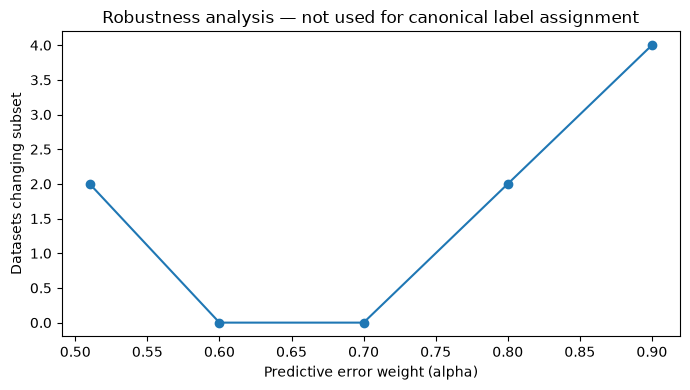

In [21]:
def compare_ranking(candidate, canonical, value, parameter):
    labels,ranks=assign_predictive_difficulty_groups(candidate)
    eligible=canonical.ranking_eligible
    assert candidate.ranking_eligible.equals(eligible), 'Robustness comparison requires the same eligible pool'
    changed=labels.loc[eligible].ne(canonical.loc[eligible,'predictive_difficulty_label'])
    rho=spearmanr(ranks.loc[eligible],canonical.loc[eligible,'predictive_difficulty_rank']).statistic
    detail=pd.DataFrame({'dataset':canonical.loc[eligible,'dataset'], parameter:value,
        'canonical_rank':canonical.loc[eligible,'predictive_difficulty_rank'],
        'alternative_rank':ranks.loc[eligible],
        'canonical_subset':canonical.loc[eligible,'predictive_difficulty_label'],
        'alternative_subset':labels.loc[eligible], 'subset_changed':changed})
    summary={parameter:value,'n_datasets':int(eligible.sum()),'spearman_rank_correlation':rho,
        'n_subset_changes':int(changed.sum()),'pct_subset_changes':100*changed.mean(),
        'label_agreement':1-changed.mean(),
        'datasets_crossing_boundaries':'; '.join(detail.loc[detail.subset_changed,'dataset'])}
    return summary, detail

weight_rows, weight_details=[],[]
for alpha in [.51,.60,.70,.80,.90]:
    alternative=canonical_snapshot_df.copy(deep=True)
    alternative['predictive_difficulty_score']=(alpha*alternative.predictive_error_score
        +(1-alpha)*alternative.cv_variability_score)
    # Use the literal canonical coefficients at the reference weight.
    if alpha == .70:
        alternative['predictive_difficulty_score']=canonical_snapshot_df.predictive_difficulty_score
    summary,detail=compare_ranking(alternative,canonical_snapshot_df,alpha,'alpha')
    weight_rows.append(summary); weight_details.append(detail)
weight_sensitivity_summary_df=pd.DataFrame(weight_rows)
weight_sensitivity_dataset_df=pd.concat(weight_details,ignore_index=True)
weight_sensitivity_summary_df.to_csv(output_dir / 'weight_sensitivity_summary.csv',index=False)
weight_sensitivity_dataset_df.to_csv(output_dir / 'weight_sensitivity_by_dataset.csv',index=False)
display(weight_sensitivity_summary_df)
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(weight_sensitivity_summary_df.alpha,weight_sensitivity_summary_df.n_subset_changes,marker='o')
ax.set(xlabel='Predictive error weight (alpha)',ylabel='Datasets changing subset',
       title='Robustness analysis — not used for canonical label assignment')
fig.tight_layout()
fig.savefig(output_dir / 'weight_sensitivity.pdf')
plt.show()

## Robustness Analysis: Sensitivity to Cross-Validation Seed

**ROBUSTNESS / SENSITIVITY ONLY.** This analysis evaluates how random generation
of repeated cross-validation partitions affects the continuous predictive-difficulty
score, dataset ranking, and categorical difficulty strata. The canonical
characterization remains the one obtained using seed **42**. Alternative seeds
never redefine or average the official Easy / Intermediate / Hard labels.

Only the CV partition seed changes. We reuse the same preprocessing pipelines,
four non-dummy models, fixed estimator random states, hyperparameters, macro-F1
scorer, and 5-fold × 3-repeat protocol. Seed 42 is **refitted**, so its reproduction
checks test the actual evaluation path rather than a copy of canonical values.

The experiment starts from the **canonical ranking-eligible population**. A
dataset–seed pair needs all four successful models with 15 finite scores each.
Failures remain in the audit; incomplete pairs have no difficulty score and are
excluded from numerical and label comparisons. Each seed normalizes E and V
over its own complete pool and applies the canonical exact-tie sorting and
approximately equal group sizes. If failures shrink a pool, the summaries flag
this: changes then reflect both CV partitions and the changed normalization pool.

Global ranking stability and local boundary sensitivity are different questions.
Category changes should be read alongside the canonical rank and proximity to
Easy/Intermediate or Intermediate/Hard boundaries. A single label change does not
by itself show that the entire methodology is unstable. Correlation p-values are
descriptive; seed runs share datasets and are not independent benchmark samples.


In [22]:
RUN_SEED_ROBUSTNESS = True
ROBUSTNESS_CV_SEEDS = [7, 21, 42, 84, 123]
SEED_REPRODUCTION_ATOL = 1e-10  # absolute tolerance; rtol=0 for reproduction checks

def evaluate_baselines_for_cv_seed(data, seed):
    """Reuse canonical evaluation without dummy fits or changes to estimator seeds."""
    model_frames, cv_audits = [], []
    for position, (name, obj) in enumerate(data.items(), start=1):
        print(f'[Seed {seed}] Evaluating dataset {position}/{len(data)}: {name}')
        models, audit = evaluate_baselines({name: obj}, cv_seed=seed, include_dummy=False)
        model_frames.append(models)
        cv_audits.append(audit)
    return pd.concat(model_frames, ignore_index=True), pd.concat(cv_audits, ignore_index=True)

def seed_model_failure_reason(rows):
    """Explain missing, duplicate, failed, or malformed model evaluations."""
    if len(rows) != 1:
        return f'Expected one model evaluation, found {len(rows)}'
    row = rows.iloc[0]
    if pd.notna(row.error) and str(row.error).strip():
        return str(row.error)
    if not successful_rows(rows).all():
        return f'Invalid CV results: n_scores={row.n_scores}; require 15 finite scores and valid mean/std'
    return ''

def build_seed_dataset_profile(model_results, cv_audit, seed):
    """Reconstruct F, E, V and normalize within this seed's complete pool."""
    assert set(model_results.model) <= set(NON_DUMMY_BASELINE_MODELS), 'Unexpected/dummy robustness model'
    model_copy = model_results.copy(deep=True)
    # Derive mu and sample sigma from retained observations, never pool algorithms.
    valid_models = successful_rows(model_copy)
    if valid_models.any():
        model_copy.loc[valid_models, 'f1_macro_mean'] = model_copy.loc[valid_models, 'scores'].map(np.mean)
        model_copy.loc[valid_models, 'f1_macro_std'] = model_copy.loc[valid_models, 'scores'].map(
            lambda scores: np.std(scores, ddof=1))
    profile = aggregate_baselines(model_copy, cv_audit).copy(deep=True)
    failure_rows = []
    for name in cv_audit.dataset:
        for model in NON_DUMMY_BASELINE_MODELS:
            rows = model_copy.loc[model_copy.dataset.eq(name) & model_copy.model.eq(model)]
            reason = seed_model_failure_reason(rows)
            if reason:
                failure_rows.append(dict(seed=seed, dataset=name, model=model,
                    n_scores=int(rows.iloc[0].n_scores) if len(rows) else 0, error=reason))
    failures = pd.DataFrame(failure_rows, columns=['seed','dataset','model','n_scores','error'])
    failure_reasons = failures.groupby('dataset').apply(
        lambda g: '; '.join(g.model + ': ' + g.error)) if len(failures) else pd.Series(dtype=object)
    profile['seed'] = seed
    profile['complete_seed_dataset'] = profile.ranking_eligible
    profile['incomplete_reason'] = profile.dataset.map(failure_reasons).fillna(profile.ranking_exclusion_reason)
    profile['predictive_error'] = 1.0 - profile.baseline_macro_f1_mean
    profile['predictive_error_score'] = minmax_normalize_on_pool(profile.predictive_error, profile.ranking_eligible)
    profile['cv_variability_score'] = minmax_normalize_on_pool(profile.cv_variability, profile.ranking_eligible)
    profile['predictive_difficulty_score'] = .70*profile.predictive_error_score + .30*profile.cv_variability_score
    # Record normalization endpoints to audit the seed-specific reference pool.
    for metric in ['predictive_error', 'cv_variability']:
        values = profile.loc[profile.ranking_eligible, metric]
        profile[metric+'_pool_min'] = values.min()
        profile[metric+'_pool_max'] = values.max()
    profile['normalization_pool_size'] = int(profile.ranking_eligible.sum())
    return profile, failures

def assign_seed_difficulty_labels(profile):
    """Call the canonical ranking helper on a separate DataFrame."""
    result = profile.copy(deep=True)
    labels, ranks = assign_predictive_difficulty_groups(result)
    result['predictive_difficulty_rank_seed'] = ranks
    result['predictive_difficulty_label_seed'] = labels.where(result.ranking_eligible, 'incomplete')
    return result

def seed_spearman(x, y):
    """Undefined correlations stay NaN for fewer than two pairs or constant inputs."""
    pairs = pd.DataFrame({'x': x, 'y': y}).replace([np.inf, -np.inf], np.nan).dropna()
    if len(pairs) < 2 or pairs.nunique().min() < 2:
        return np.nan, np.nan
    result = spearmanr(pairs.x, pairs.y)
    return float(result.statistic), float(result.pvalue)

def compare_seed_profiles(seed_profiles, canonical):
    reference = canonical.loc[canonical.ranking_eligible,
        ['dataset','predictive_difficulty_rank','predictive_difficulty_label','predictive_difficulty_score']].rename(
        columns={'predictive_difficulty_rank':'canonical_rank',
                 'predictive_difficulty_label':'canonical_label',
                 'predictive_difficulty_score':'canonical_D_pred'})
    candidate = seed_profiles[['dataset','seed','complete_seed_dataset','incomplete_reason',
        'predictive_difficulty_rank_seed','predictive_difficulty_label_seed',
        'predictive_difficulty_score']].rename(columns={
            'predictive_difficulty_rank_seed':'robustness_rank',
            'predictive_difficulty_label_seed':'robustness_label',
            'predictive_difficulty_score':'robustness_D_pred'})
    comparison = candidate.merge(reference, on='dataset', validate='many_to_one')
    comparison['comparison_eligible'] = comparison.complete_seed_dataset
    comparison['rank_difference'] = comparison.robustness_rank - comparison.canonical_rank
    comparison['D_pred_difference'] = comparison.robustness_D_pred - comparison.canonical_D_pred
    comparison['label_changed'] = comparison.robustness_label.ne(comparison.canonical_label).astype('boolean')
    comparison.loc[~comparison.comparison_eligible, 'label_changed'] = pd.NA
    summaries = []
    for seed, group in comparison.groupby('seed', sort=False):
        complete = group.loc[group.comparison_eligible]
        n = len(complete)
        rank_rho, rank_p = seed_spearman(complete.canonical_rank, complete.robustness_rank)
        score_rho, score_p = seed_spearman(complete.canonical_D_pred, complete.robustness_D_pred)
        changed = int(complete.label_changed.sum())
        absolute_change = complete.rank_difference.abs()
        summaries.append(dict(seed=seed, is_canonical_seed=seed == 42,
            n_canonical_datasets=len(reference), n_complete_datasets=n,
            n_incomplete_datasets=len(group)-n, n_datasets_compared=n,
            comparison_uses_full_canonical_pool=n == len(reference),
            spearman_rank_correlation_vs_42=rank_rho, p_value=rank_p,
            spearman_score_correlation_vs_42=score_rho, score_p_value=score_p,
            n_same_label=n-changed, n_changed_label=changed,
            percent_same_label=100*(n-changed)/n if n else np.nan,
            percent_changed_label=100*changed/n if n else np.nan,
            n_label_changes_vs_42=changed, percent_label_changes_vs_42=100*changed/n if n else np.nan,
            mean_absolute_rank_change=absolute_change.mean(), max_absolute_rank_change=absolute_change.max()))
    return pd.DataFrame(summaries), comparison.sort_values(['seed','canonical_rank']).reset_index(drop=True)

def summarize_seed_dataset_stability(comparison):
    rows = []
    for name, group in comparison.groupby('dataset', sort=False):
        complete = group.loc[group.comparison_eligible]
        first = group.iloc[0]
        observed = set(complete.robustness_label)
        rows.append(dict(dataset=name, canonical_rank=first.canonical_rank,
            canonical_label=first.canonical_label, n_seeds_requested=len(group),
            n_complete_seeds=len(complete), n_incomplete_seeds=len(group)-len(complete),
            n_alternative_seeds_compared=int(complete.seed.ne(42).sum()),
            mean_rank_across_seeds=complete.robustness_rank.mean(),
            std_rank_across_seeds=complete.robustness_rank.std(ddof=1),
            min_rank=complete.robustness_rank.min(), max_rank=complete.robustness_rank.max(),
            mean_D_pred_across_seeds=complete.robustness_D_pred.mean(),
            std_D_pred_across_seeds=complete.robustness_D_pred.std(ddof=1),
            n_label_changes_vs_canonical=int(complete.label_changed.sum()),
            proportion_same_label_as_canonical=1-float(complete.label_changed.mean()) if len(complete) else np.nan,
            labels_observed=', '.join(label.capitalize() for label in ['easy','intermediate','hard'] if label in observed),
            max_absolute_rank_change=complete.rank_difference.abs().max()))
    return pd.DataFrame(rows).sort_values('canonical_rank').reset_index(drop=True)


### Run the five partition seeds and export independent results

The successful comparison denominator is reported for every seed and dataset.
Across-seed means and sample standard deviations include the refitted reference
seed 42 and exclude incomplete pairs. Label-change counts include the reference
(which must contribute zero); plots also show the number of complete alternative
seeds. No failure is counted as agreement or a category change.


In [23]:
# SEED ROBUSTNESS: execution and exports (all writes confined to robustness/).
if RUN_SEED_ROBUSTNESS:
    import copy
    import hashlib
    import pickle

    # Fingerprint all canonical/global DataFrames, model configurations, and raw
    # loaded datasets before the experiment. This also detects nested-list changes.
    seed_guard_names = [name for name, value in list(globals().items())
        if isinstance(value, pd.DataFrame) and not name.startswith('seed_')]
    seed_guard_names += ['loaded', 'MODEL_CONFIGS', 'CV_RANDOM_STATE', 'CV_N_SPLITS',
                         'CV_N_REPEATS', 'N_JOBS', 'NON_DUMMY_BASELINE_MODELS']
    seed_guard_fingerprints = {name: hashlib.sha256(pickle.dumps(globals()[name])).hexdigest()
                               for name in seed_guard_names}
    seed_reference_df = copy.deepcopy(dataset_profile_df.loc[dataset_profile_df.ranking_eligible])
    seed_reference_df = seed_reference_df.sort_values('predictive_difficulty_rank').reset_index(drop=True)
    assert CV_RANDOM_STATE == 42, 'Canonical CV_RANDOM_STATE must remain 42'
    assert seed_reference_df.min_class_count.ge(5).all() and seed_reference_df.comparable_cv.all()
    assert len(seed_reference_df) > 0, 'No canonical eligible datasets available for seed robustness'
    seed_data = {name: loaded[name] for name in seed_reference_df.dataset}
    seed_output_dir = output_dir / 'robustness'
    seed_output_dir.mkdir(parents=True, exist_ok=True)
    seed_model_frames, seed_profile_frames, seed_failure_frames, seed_cv_audit_frames = [], [], [], []
    for seed_value in ROBUSTNESS_CV_SEEDS:
        seed_models, seed_cv_audit = evaluate_baselines_for_cv_seed(seed_data, seed_value)
        seed_models['seed'] = seed_value
        seed_profile, seed_failures = build_seed_dataset_profile(seed_models, seed_cv_audit, seed_value)
        seed_profile = assign_seed_difficulty_labels(seed_profile)
        seed_model_frames.append(seed_models)
        seed_profile_frames.append(seed_profile)
        seed_failure_frames.append(seed_failures)
        seed_cv_audit_frames.append(seed_cv_audit)
    seed_robustness_model_results_df = pd.concat(seed_model_frames, ignore_index=True)
    seed_robustness_dataset_scores_df = pd.concat(seed_profile_frames, ignore_index=True)
    seed_robustness_failures_df = pd.concat(seed_failure_frames, ignore_index=True)
    seed_robustness_cv_audit_df = pd.concat(seed_cv_audit_frames, ignore_index=True)
    seed_robustness_summary_df, seed_robustness_comparison_vs_canonical_df = compare_seed_profiles(
        seed_robustness_dataset_scores_df, seed_reference_df)
    seed_robustness_dataset_summary_df = summarize_seed_dataset_stability(seed_robustness_comparison_vs_canonical_df)
    seed_exports = {
        'seed_robustness_model_results.csv': seed_robustness_model_results_df,
        'seed_robustness_dataset_scores.csv': seed_robustness_dataset_scores_df,
        'seed_robustness_comparison_vs_canonical.csv': seed_robustness_comparison_vs_canonical_df,
        'seed_robustness_summary.csv': seed_robustness_summary_df,
        'seed_robustness_dataset_summary.csv': seed_robustness_dataset_summary_df,
        'seed_robustness_failures.csv': seed_robustness_failures_df,
        'seed_robustness_cv_audit.csv': seed_robustness_cv_audit_df,
    }
    for seed_filename, seed_export_df in seed_exports.items():
        seed_export_df.to_csv(seed_output_dir / seed_filename, index=False)
    print(f'Seed robustness results saved to {seed_output_dir}')
else:
    print('CV-seed robustness disabled. Canonical seed-42 characterization is unchanged.')


[Seed 7] Evaluating dataset 1/17: banknote


[WARNINGS] banknote/logistic_regression: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
[WARNINGS] banknote/logistic_regression_balanced: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
CV seed 7: banknote completed; comparable=True
[Seed 7] Evaluating dataset 2/17: tic_tac_toe


[WARNINGS] tic_tac_toe/logistic_regression: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i


[WARNINGS] tic_tac_toe/logistic_regression_balanced: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
CV seed 7: tic_tac_toe completed; comparable=True
[Seed 7] Evaluating dataset 3/17: breast_cancer


[WARNINGS] breast_cancer/logistic_regression: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
[WARNINGS] breast_cancer/logistic_regression_balanced: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
CV seed 7: breast_cancer completed; comparable=True
[Seed 7] Evaluating dataset 4/17: iris


[WARNINGS] iris/logistic_regression: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
[WARNINGS] iris/logistic_regression_balanced: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
CV seed 7: iris completed; comparable=True
[Seed 7] Evaluating dataset 5/17: semeion


... (123 outputs left out)

[WARNINGS] wine_red/logistic_regression: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i


[WARNINGS] wine_red/logistic_regression_balanced: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
CV seed 123: wine_red completed; comparable=True
[Seed 123] Evaluating dataset 17/17: heart_disease


[WARNINGS] heart_disease/logistic_regression: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
[WARNINGS] heart_disease/logistic_regression_balanced: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 i
CV seed 123: heart_disease completed; comparable=True


Seed robustness results saved to C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\results\dataset_statistics\robustness


### Robustness assertions

Seed 42 must reproduce F, V, normalized D_pred, rank, and labels. Complete
dataset–seed pairs must contain exactly four valid non-dummy model evaluations.
Incomplete pairs remain auditable and never enter score/label comparisons.
Canonical object fingerprints must match before and after the entire experiment.


In [24]:
# SEED ROBUSTNESS: assertions, with auditable PASS/FAIL output.
if RUN_SEED_ROBUSTNESS:
    seed_checks = []
    def check_seed_robustness(name, condition):
        seed_checks.append(dict(check=name, passed=bool(condition)))
        print(('PASS' if condition else 'FAIL') + ': ' + name)

    seed42_profile = seed_robustness_dataset_scores_df.loc[
        seed_robustness_dataset_scores_df.seed.eq(42)].set_index('dataset').reindex(seed_reference_df.dataset)
    seed42_reference = seed_reference_df.set_index('dataset')
    for seed_metric in ['baseline_macro_f1_mean', 'cv_variability', 'predictive_difficulty_score']:
        check_seed_robustness('Seed 42 reproduces '+seed_metric,
            np.allclose(seed42_profile[seed_metric], seed42_reference[seed_metric],
                        atol=SEED_REPRODUCTION_ATOL, rtol=0))
    check_seed_robustness('Seed 42 reproduces rank ordering', np.array_equal(
        seed42_profile.predictive_difficulty_rank_seed, seed42_reference.predictive_difficulty_rank))
    check_seed_robustness('Seed 42 reproduces exact subset labels', np.array_equal(
        seed42_profile.predictive_difficulty_label_seed, seed42_reference.predictive_difficulty_label))
    seed_success_mask = successful_rows(seed_robustness_model_results_df)
    seed_claimed_success = seed_robustness_model_results_df.error.fillna('').eq('')
    check_seed_robustness('Every successful model evaluation has exactly 15 finite scores',
        seed_success_mask.loc[seed_claimed_success].all())
    seed_complete_keys = seed_robustness_dataset_scores_df.loc[
        seed_robustness_dataset_scores_df.complete_seed_dataset, ['seed','dataset']]
    seed_complete_models = seed_complete_keys.merge(seed_robustness_model_results_df,
        on=['seed','dataset'], how='left', validate='one_to_many')
    check_seed_robustness('All complete pairs contain all four successful non-dummy models',
        seed_complete_models.groupby(['seed','dataset']).apply(lambda g:
            len(g) == 4 and set(g.model) == set(NON_DUMMY_BASELINE_MODELS)
            and successful_rows(g).all()).all())
    check_seed_robustness('Dummy models absent from robustness calculations',
        set(seed_robustness_model_results_df.model) == set(NON_DUMMY_BASELINE_MODELS))
    check_seed_robustness('Incomplete pairs have no D_pred, rank, or label comparison',
        seed_robustness_comparison_vs_canonical_df.loc[
            ~seed_robustness_comparison_vs_canonical_df.comparison_eligible,
            ['robustness_D_pred','robustness_rank','label_changed']].isna().all().all())
    check_seed_robustness('All canonical variables and inputs unchanged', all(
        hashlib.sha256(pickle.dumps(globals()[name])).hexdigest() == fingerprint
        for name, fingerprint in seed_guard_fingerprints.items()))
    seed_robustness_assertions_df = pd.DataFrame(seed_checks)
    seed_robustness_assertions_df.to_csv(seed_output_dir / 'seed_robustness_assertions.csv', index=False)
    seed_failed_checks = seed_robustness_assertions_df.loc[~seed_robustness_assertions_df.passed, 'check'].tolist()
    assert not seed_failed_checks, 'Seed robustness assertions failed: ' + '; '.join(seed_failed_checks)


PASS: Seed 42 reproduces baseline_macro_f1_mean
PASS: Seed 42 reproduces cv_variability
PASS: Seed 42 reproduces predictive_difficulty_score
PASS: Seed 42 reproduces rank ordering
PASS: Seed 42 reproduces exact subset labels
PASS: Every successful model evaluation has exactly 15 finite scores
PASS: All complete pairs contain all four successful non-dummy models
PASS: Dummy models absent from robustness calculations
PASS: Incomplete pairs have no D_pred, rank, or label comparison
PASS: All canonical variables and inputs unchanged


### Rank trajectories, boundary crossings, and score dispersion

Seeds are discrete partition choices, so the trajectory x-axis uses equally
spaced seed labels. Missing pairs break trajectories and are excluded from
frequency denominators. Horizontal rank guides mark the canonical subset
boundaries; if a seed has an incomplete pool its own group cutoffs may differ.
The label-change plot reports counts across complete alternative seeds, with
each dataset's denominator shown. Score ranges include all complete seeds,
including 42, and are descriptive ranges rather than confidence intervals.


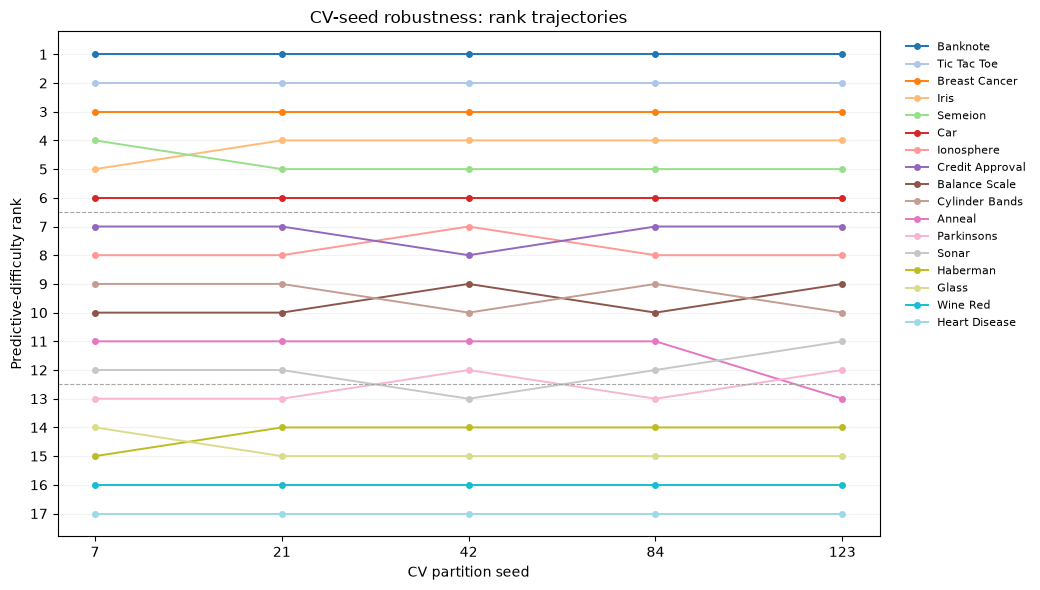

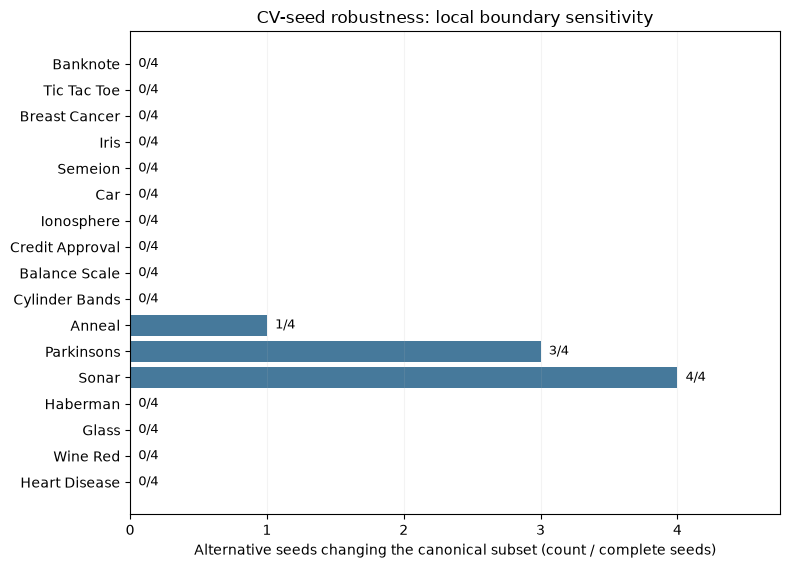

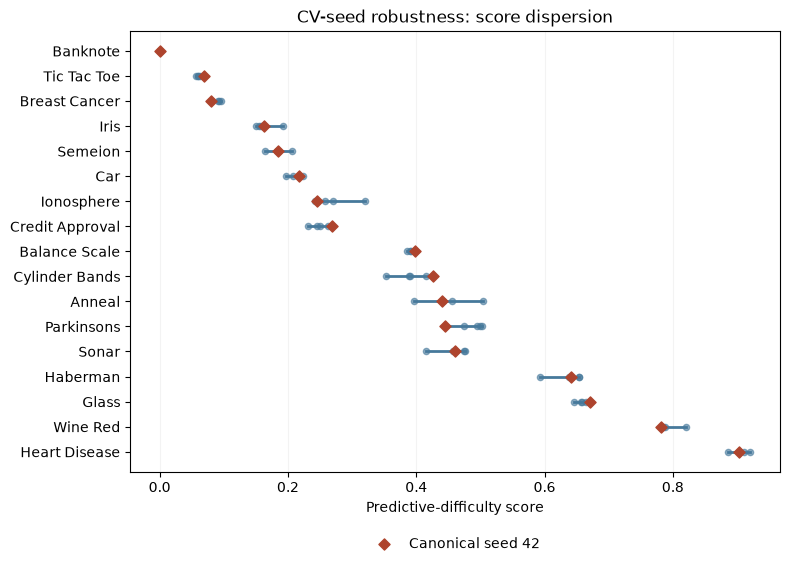

In [25]:
# SEED ROBUSTNESS: publication-friendly figures; no canonical score assignments.
if RUN_SEED_ROBUSTNESS:
    seed_plot_order = seed_reference_df.dataset.tolist()
    seed_plot_labels = [name.replace('_', ' ').title() for name in seed_plot_order]
    seed_positions = np.arange(len(ROBUSTNESS_CV_SEEDS))
    seed_colors = plt.get_cmap('tab20')(np.linspace(0, 1, len(seed_plot_order)))
    seed_rank_matrix = seed_robustness_comparison_vs_canonical_df.pivot(
        index='seed', columns='dataset', values='robustness_rank').reindex(ROBUSTNESS_CV_SEEDS)
    seed_fig, seed_ax = plt.subplots(figsize=(10.5, max(6, .32*len(seed_plot_order))))
    for seed_i, seed_name in enumerate(seed_plot_order):
        seed_ax.plot(seed_positions, seed_rank_matrix[seed_name], marker='o', markersize=4,
            linewidth=1.4, color=seed_colors[seed_i], label=seed_plot_labels[seed_i])
    seed_group_sizes = seed_reference_df.predictive_difficulty_label.value_counts().reindex(
        ['easy','intermediate','hard'], fill_value=0)
    for seed_boundary in seed_group_sizes.cumsum().iloc[:-1]:
        seed_ax.axhline(seed_boundary+.5, color='.65', linestyle='--', linewidth=.8)
    seed_ax.set_xticks(seed_positions, [str(s) for s in ROBUSTNESS_CV_SEEDS])
    seed_ax.set_yticks(np.arange(1, len(seed_plot_order)+1))
    seed_ax.invert_yaxis()
    seed_ax.set(xlabel='CV partition seed', ylabel='Predictive-difficulty rank',
                title='CV-seed robustness: rank trajectories')
    seed_ax.grid(axis='y', alpha=.15)
    seed_ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False, fontsize=8)
    seed_fig.tight_layout()
    seed_fig.savefig(seed_output_dir / 'cv_seed_rank_stability.pdf', bbox_inches='tight')
    plt.show()

    seed_bar_data = seed_robustness_dataset_summary_df.set_index('dataset').loc[seed_plot_order]
    seed_fig, seed_ax = plt.subplots(figsize=(8, max(5, .34*len(seed_plot_order))))
    seed_ax.barh(seed_plot_labels, seed_bar_data.n_label_changes_vs_canonical, color='#46799B')
    for seed_i, (_, seed_row) in enumerate(seed_bar_data.iterrows()):
        seed_ax.text(seed_row.n_label_changes_vs_canonical+.06, seed_i,
            f'{int(seed_row.n_label_changes_vs_canonical)}/{int(seed_row.n_alternative_seeds_compared)}',
            va='center', fontsize=9)
    seed_ax.invert_yaxis()
    seed_ax.set_xticks(np.arange(len(ROBUSTNESS_CV_SEEDS)))
    seed_ax.set_xlim(0, len(ROBUSTNESS_CV_SEEDS)-.25)
    seed_ax.set(xlabel='Alternative seeds changing the canonical subset (count / complete seeds)',
                title='CV-seed robustness: local boundary sensitivity')
    seed_ax.grid(axis='x', alpha=.15)
    seed_fig.tight_layout()
    seed_fig.savefig(seed_output_dir / 'cv_seed_label_stability.pdf', bbox_inches='tight')
    plt.show()

    seed_fig, seed_ax = plt.subplots(figsize=(8, max(5, .34*len(seed_plot_order))))
    for seed_i, seed_name in enumerate(seed_plot_order):
        seed_observations = seed_robustness_comparison_vs_canonical_df.loc[
            seed_robustness_comparison_vs_canonical_df.dataset.eq(seed_name)
            & seed_robustness_comparison_vs_canonical_df.comparison_eligible, 'robustness_D_pred']
        if len(seed_observations):
            seed_ax.plot([seed_observations.min(), seed_observations.max()], [seed_i, seed_i],
                         color='#46799B', linewidth=2)
            seed_ax.scatter(seed_observations, [seed_i]*len(seed_observations),
                            color='#46799B', alpha=.6, s=20)
    seed_ax.scatter(seed_reference_df.predictive_difficulty_score, np.arange(len(seed_plot_order)),
                    marker='D', s=32, color='#AE442D', label='Canonical seed 42', zorder=3)
    seed_ax.set_yticks(np.arange(len(seed_plot_order)), seed_plot_labels)
    seed_ax.invert_yaxis()
    seed_ax.set(xlabel='Predictive-difficulty score', title='CV-seed robustness: score dispersion')
    seed_ax.grid(axis='x', alpha=.15)
    seed_ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(.5, -.12))
    seed_fig.tight_layout()
    seed_fig.savefig(seed_output_dir / 'cv_seed_predictive_difficulty_stability.pdf', bbox_inches='tight')
    plt.show()


In [26]:
# SEED ROBUSTNESS: neutral, data-driven interpretation and final displays.
if RUN_SEED_ROBUSTNESS:
    seed_alternatives = seed_robustness_summary_df.loc[~seed_robustness_summary_df.is_canonical_seed]
    seed_changed_datasets = seed_robustness_dataset_summary_df.loc[
        seed_robustness_dataset_summary_df.n_label_changes_vs_canonical.gt(0), 'dataset'].tolist()
    seed_largest_variation = seed_robustness_dataset_summary_df.sort_values(
        ['max_absolute_rank_change', 'std_rank_across_seeds', 'dataset'], ascending=[False,False,True]).head(5)
    print(f'Evaluated {len(ROBUSTNESS_CV_SEEDS)} CV seeds; seed 42 remains the official characterization.')
    print(f'Alternative-seed rank correlation: minimum = {seed_alternatives.spearman_rank_correlation_vs_42.min():.4f}; '
          f'mean = {seed_alternatives.spearman_rank_correlation_vs_42.mean():.4f}.')
    print(f'Maximum subset changes for an alternative seed: {seed_alternatives.n_label_changes_vs_42.max()}.')
    print('Datasets changing label at least once: ' + (', '.join(seed_changed_datasets) or 'none') + '.')
    print('Largest absolute rank changes: ' + '; '.join(
        f'{row.dataset}: {row.max_absolute_rank_change:g}' for row in seed_largest_variation.itertuples()) + '.')
    if seed_alternatives.n_incomplete_datasets.sum():
        print('Some seed pools are incomplete. Consult failures and comparison denominators; pool changes can affect normalization and boundaries.')
    print('Interpret global rank correlations separately from local subset-boundary crossings; alternative seeds do not redefine official labels.')
    assert all(hashlib.sha256(pickle.dumps(globals()[name])).hexdigest() == fingerprint
               for name, fingerprint in seed_guard_fingerprints.items()), 'Canonical variables changed during robustness reporting'
    display(seed_robustness_summary_df)
    display(seed_robustness_dataset_summary_df)
    display(seed_robustness_comparison_vs_canonical_df)


Evaluated 5 CV seeds; seed 42 remains the official characterization.
Alternative-seed rank correlation: minimum = 0.9877; mean = 0.9902.
Maximum subset changes for an alternative seed: 2.
Datasets changing label at least once: anneal, parkinsons, sonar.
Largest absolute rank changes: anneal: 2; sonar: 2; balance_scale: 1; cylinder_bands: 1; parkinsons: 1.
Interpret global rank correlations separately from local subset-boundary crossings; alternative seeds do not redefine official labels.


,seed,is_canonical_seed,n_canonical_datasets,n_complete_datasets,n_incomplete_datasets,n_datasets_compared,comparison_uses_full_canonical_pool,spearman_rank_correlation_vs_42,p_value,spearman_score_correlation_vs_42,score_p_value,n_same_label,n_changed_label,percent_same_label,percent_changed_label,n_label_changes_vs_42,percent_label_changes_vs_42,mean_absolute_rank_change,max_absolute_rank_change
0,7,False,17,17,0,17,True,0.987745,1.627083e-13,0.987745,1.627083e-13,15,2,88.235294,11.764706,2,11.764706,0.588235,1.0
1,21,False,17,17,0,17,True,0.992647,3.578274e-15,0.992647,3.578274e-15,15,2,88.235294,11.764706,2,11.764706,0.352941,1.0
2,42,True,17,17,0,17,True,1.000000,0.000000e+00,1.000000,0.000000e+00,17,0,100.000000,0.000000,0,0.000000,0.000000,0.0
3,84,False,17,17,0,17,True,0.992647,3.578274e-15,0.992647,3.578274e-15,15,2,88.235294,11.764706,2,11.764706,0.352941,1.0
4,123,False,17,17,0,17,True,0.987745,1.627083e-13,0.987745,1.627083e-13,15,2,88.235294,11.764706,2,11.764706,0.352941,2.0


,dataset,canonical_rank,canonical_label,n_seeds_requested,n_complete_seeds,n_incomplete_seeds,n_alternative_seeds_compared,mean_rank_across_seeds,std_rank_across_seeds,min_rank,max_rank,mean_D_pred_across_seeds,std_D_pred_across_seeds,n_label_changes_vs_canonical,proportion_same_label_as_canonical,labels_observed,max_absolute_rank_change
0,banknote,1.0,easy,5,5,0,4,1.0,0.000000,1.0,1.0,0.000000,0.000000,0,1.0,Easy,0.0
1,tic_tac_toe,2.0,easy,5,5,0,4,2.0,0.000000,2.0,2.0,0.061959,0.004449,0,1.0,Easy,0.0
2,breast_cancer,3.0,easy,5,5,0,4,3.0,0.000000,3.0,3.0,0.088339,0.007153,0,1.0,Easy,0.0
3,iris,4.0,easy,5,5,0,4,4.2,0.447214,4.0,5.0,0.163654,0.016399,0,1.0,Easy,1.0
4,semeion,5.0,easy,5,5,0,4,4.8,0.447214,4.0,5.0,0.184539,0.014902,0,1.0,Easy,1.0
5,car,6.0,easy,5,5,0,4,6.0,0.000000,6.0,6.0,0.212861,0.010476,0,1.0,Easy,0.0
6,ionosphere,7.0,intermediate,5,5,0,4,7.8,0.447214,7.0,8.0,0.267172,0.031431,0,1.0,Intermediate,1.0
7,credit_approval,8.0,intermediate,5,5,0,4,7.2,0.447214,7.0,8.0,0.251422,0.014401,0,1.0,Intermediate,1.0
8,balance_scale,9.0,intermediate,5,5,0,4,9.6,0.547723,9.0,10.0,0.392642,0.004884,0,1.0,Intermediate,1.0
9,cylinder_bands,10.0,intermediate,5,5,0,4,9.4,0.547723,9.0,10.0,0.394463,0.028193,0,1.0,Intermediate,1.0


,dataset,seed,complete_seed_dataset,incomplete_reason,robustness_rank,robustness_label,robustness_D_pred,canonical_rank,canonical_label,canonical_D_pred,comparison_eligible,rank_difference,D_pred_difference,label_changed
0,banknote,7,True,,1.0,easy,0.000000,1.0,easy,0.000000,True,0.0,0.000000,False
1,tic_tac_toe,7,True,,2.0,easy,0.060445,2.0,easy,0.068858,True,0.0,-0.008413,False
2,breast_cancer,7,True,,3.0,easy,0.091631,3.0,easy,0.080834,True,0.0,0.010797,False
3,iris,7,True,,5.0,easy,0.191617,4.0,easy,0.163358,True,1.0,0.028259,False
4,semeion,7,True,,4.0,easy,0.182584,5.0,easy,0.184030,True,-1.0,-0.001446,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,sonar,123,True,,11.0,intermediate,0.415448,13.0,hard,0.460279,True,-2.0,-0.044831,True
81,haberman,123,True,,14.0,hard,0.637448,14.0,hard,0.640520,True,0.0,-0.003072,False
82,glass,123,True,,15.0,hard,0.657288,15.0,hard,0.670432,True,0.0,-0.013145,False
83,wine_red,123,True,,16.0,hard,0.784903,16.0,hard,0.781354,True,0.0,0.003549,False


**EXPLORATORY / SUPPORTING DESCRIPTORS — never used to assign labels.**

## 14. Dataset similarity based on class distributions

Uses Jensen-Shannon distance between class distributions. This is a rough comparison because datasets may have different numbers of classes.

In [23]:
# EXPLORATORY: frequency shapes, independent of semantic class labels.
names = list(loaded)
max_classes = max(len(np.unique(loaded[n]['y'])) for n in names)
def class_frequency_profile(y, width):
    proportions = pd.Series(y).value_counts(normalize=True).to_numpy()
    return np.pad(np.sort(proportions)[::-1], (0, width-len(proportions)))
class_vectors = {n: class_frequency_profile(loaded[n]['y'], max_classes) for n in names}
for n in names:
    y = loaded[n]['y']
    permuted = np.max(y) - y
    assert np.array_equal(class_vectors[n], class_frequency_profile(permuted, max_classes))
    for other in names:
        assert jensenshannon(class_vectors[n], class_vectors[other]) == jensenshannon(
            class_frequency_profile(permuted, max_classes), class_vectors[other])
similarity_matrix = pd.DataFrame([[jensenshannon(class_vectors[a], class_vectors[b])
    for b in names] for a in names], index=names, columns=names)
similarity_matrix.to_csv(output_dir / 'class_distribution_js_distance.csv')
print('PASS: class-label permutation leaves frequency profiles and distances unchanged')
display(similarity_matrix)


PASS: class-label permutation leaves frequency profiles and distances unchanged


,abalone,anneal,arrhythmia,bridges,balance_scale,car,cylinder_bands,glass,heart_disease,ionosphere,semeion,sonar,tic_tac_toe,breast_cancer,wine_red,iris,haberman,parkinsons,banknote,credit_approval
abalone,0.000000,0.505466,0.308838,0.313491,0.520395,0.515917,0.575076,0.365462,0.418834,0.577520,0.270132,0.574422,0.578223,0.576837,0.444911,0.492945,0.584962,0.587071,0.574640,0.574635
anneal,0.505466,0.000000,0.260715,0.318115,0.307890,0.128668,0.315258,0.312831,0.174587,0.285667,0.585598,0.336964,0.280114,0.291859,0.270370,0.367043,0.246577,0.239985,0.326172,0.326330
arrhythmia,0.308838,0.260715,0.000000,0.208992,0.382685,0.298501,0.411408,0.283096,0.246973,0.396263,0.399245,0.423523,0.393624,0.399286,0.315411,0.403263,0.379487,0.377195,0.417403,0.417491
bridges,0.313491,0.318115,0.208992,0.000000,0.396839,0.344351,0.442449,0.190255,0.231725,0.435600,0.396343,0.448937,0.434619,0.436818,0.303713,0.398050,0.431540,0.431767,0.445571,0.445619
balance_scale,0.520395,0.307890,0.382685,0.396839,0.000000,0.223458,0.175766,0.275951,0.300000,0.194280,0.605287,0.168864,0.198985,0.189507,0.147133,0.229672,0.237651,0.248143,0.171605,0.171555
car,0.515917,0.128668,0.298501,0.344351,0.223458,0.000000,0.213517,0.294916,0.204045,0.188810,0.598092,0.233731,0.184742,0.193599,0.217190,0.343209,0.167384,0.166360,0.223523,0.223671
cylinder_bands,0.575076,0.315258,0.411408,0.442449,0.175766,0.213517,0.000000,0.355760,0.347921,0.045853,0.649102,0.031401,0.055029,0.035872,0.258110,0.367074,0.117669,0.132553,0.015971,0.016199
glass,0.365462,0.312831,0.283096,0.190255,0.275951,0.294916,0.355760,0.000000,0.193897,0.362352,0.464807,0.353966,0.364221,0.360524,0.158710,0.291346,0.381593,0.386839,0.354567,0.354554
heart_disease,0.418834,0.174587,0.246973,0.231725,0.300000,0.204045,0.347921,0.193897,0.000000,0.336194,0.516101,0.358461,0.334411,0.338354,0.208644,0.324402,0.327692,0.327560,0.353042,0.353119
ionosphere,0.577520,0.285667,0.396263,0.435600,0.194280,0.188810,0.045853,0.362352,0.336194,0.000000,0.650953,0.077195,0.009189,0.009990,0.268583,0.374799,0.072051,0.087025,0.061800,0.062028


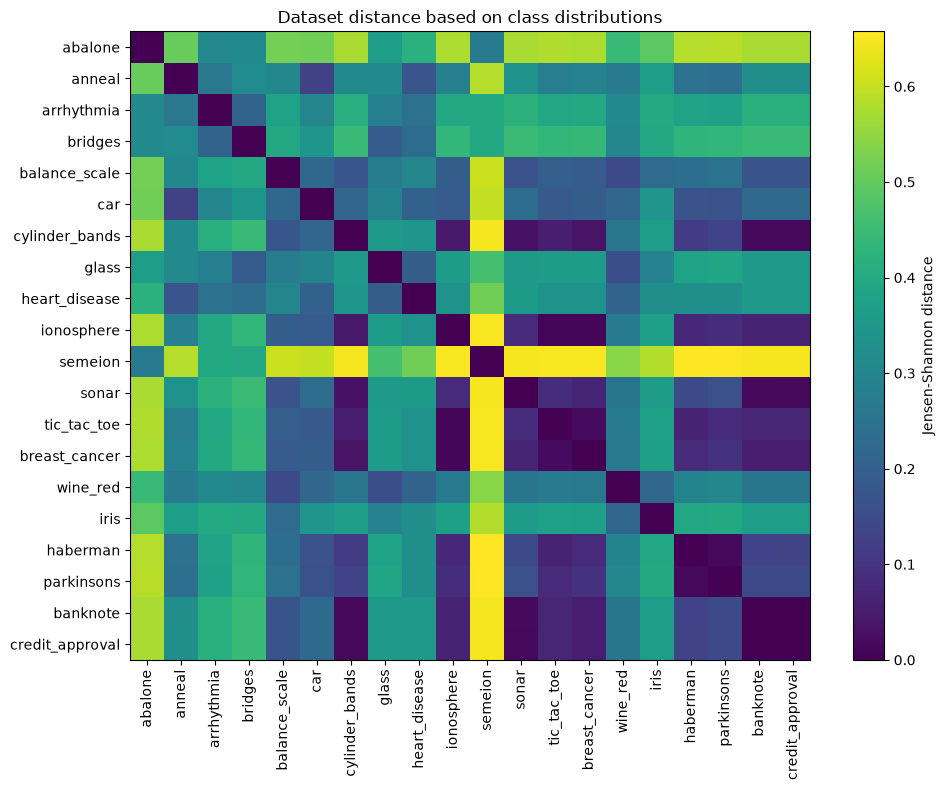

In [24]:
plt.figure(figsize=(10, 8))
plt.imshow(similarity_matrix.astype(float), aspect="auto")
plt.colorbar(label="Jensen-Shannon distance")
plt.xticks(range(len(names)), names, rotation=90)
plt.yticks(range(len(names)), names)
plt.title("Dataset distance based on class distributions")
plt.tight_layout()
plt.show()


**EXPLORATORY / SUPPORTING DESCRIPTORS — never used to assign labels.**

## 15. Thesis-oriented interpretation table

This final table merges the most useful indicators for discussion.
`possible_issue` thresholds are heuristic interpretation aids only, outside the paper-defined classification.


In [25]:
tree_baselines = baseline_df[
    baseline_df["model"].isin(["decision_tree_default", "decision_tree_balanced"])
].pivot_table(
    index="dataset",
    columns="model",
    values=["f1_macro_mean", "f1_macro_std"],
    aggfunc="first",
)

tree_baselines.columns = [
    f"{model}_{metric}".replace("decision_tree_", "tree_")
    for metric, model in tree_baselines.columns
]
tree_baselines = tree_baselines.reset_index()

# Read canonical quantities directly; heuristic flags below cannot change them.
final_interpretation_df = summary_df.merge(tree_baselines, on='dataset', how='left').merge(
    dataset_profile_df, on='dataset', how='left', validate='one_to_one')

# Backward-compatible names for the default tree baseline.
if "tree_default_f1_macro_mean" in final_interpretation_df.columns:
    final_interpretation_df["baseline_tree_f1_mean"] = final_interpretation_df["tree_default_f1_macro_mean"]
if "tree_default_f1_macro_std" in final_interpretation_df.columns:
    final_interpretation_df["baseline_tree_f1_std"] = final_interpretation_df["tree_default_f1_macro_std"]

# Backward-compatible difficulty column, now explicitly predictive rather than
# broad experimental challenge.
final_interpretation_df["tree_difficulty_revised"] = final_interpretation_df["predictive_difficulty_label"]

final_interpretation_df["possible_issue"] = ""
final_interpretation_df.loc[final_interpretation_df["imbalance_ratio"] > 2, "possible_issue"] += "class imbalance; "
final_interpretation_df.loc[final_interpretation_df["missing_pct"] > 5, "possible_issue"] += "missing values; "
final_interpretation_df.loc[final_interpretation_df["samples_per_feature"] < 10, "possible_issue"] += "low samples/features ratio; "
final_interpretation_df.loc[final_interpretation_df["comparable_cv"] == False, "possible_issue"] += "not eligible for fixed 5-fold CV; "
final_interpretation_df.loc[final_interpretation_df["cv_variability"] > 0.10, "possible_issue"] += "high within-model CV variability; "
final_interpretation_df.loc[final_interpretation_df["baseline_macro_f1_spread"] > 0.20, "possible_issue"] += "large strategy sensitivity; "
final_interpretation_df.loc[final_interpretation_df["computational_burden_score"] > 0.66, "possible_issue"] += "high computational burden; "

final_interpretation_df["possible_issue"] = final_interpretation_df["possible_issue"].replace("", "none obvious")

final_interpretation_df.to_csv(output_dir / "thesis_dataset_interpretation_summary.csv", index=False)
final_interpretation_df.sort_values(["predictive_difficulty_label", "baseline_macro_f1_mean"], ascending=[True, False])


,dataset,n_samples,n_features,n_numeric,n_categorical,n_classes,missing_pct,class_entropy,imbalance_ratio,samples_per_feature,...,runtime_burden_score,tree_size_burden_score,computational_burden_score,predictive_difficulty_label,predictive_difficulty_rank,difficulty_label_assignment_note,baseline_tree_f1_mean,baseline_tree_f1_std,tree_difficulty_revised,possible_issue
4,banknote,1372,4,4,0,2,0.000000,0.991128,1.249180,343.000000,...,0.014177,0.056934,0.035555,easy,1.0,Relative benchmark-pool strata assigned from D...,0.981807,0.008156,easy,none obvious
14,iris,150,4,4,0,3,0.000000,1.584963,1.000000,37.500000,...,0.005013,0.000000,0.002506,easy,4.0,Relative benchmark-pool strata assigned from D...,0.948693,0.043535,easy,none obvious
5,breast_cancer,569,30,30,0,2,0.000000,0.952635,1.683962,18.966667,...,0.052075,0.032316,0.042196,easy,3.0,Relative benchmark-pool strata assigned from D...,0.923010,0.031058,easy,none obvious
18,tic_tac_toe,958,9,0,9,2,0.000000,0.930954,1.885542,106.444444,...,0.099465,0.176599,0.138032,easy,2.0,Relative benchmark-pool strata assigned from D...,0.923480,0.020787,easy,none obvious
7,car,1728,6,0,6,4,0.000000,1.205741,18.615385,288.000000,...,0.183158,0.280392,0.231775,easy,6.0,Relative benchmark-pool strata assigned from D...,0.923959,0.032338,easy,class imbalance;
16,semeion,1593,256,256,0,10,0.000000,3.321819,1.045161,6.222656,...,1.000000,0.604315,0.802158,easy,5.0,Relative benchmark-pool strata assigned from D...,0.751055,0.018719,easy,low samples/features ratio; high computational...
17,sonar,208,60,60,0,2,0.000000,0.996730,1.144330,3.466667,...,0.056285,0.032411,0.044348,hard,13.0,Relative benchmark-pool strata assigned from D...,0.716036,0.056387,hard,low samples/features ratio;
10,glass,214,9,9,0,6,0.000000,2.176534,8.444444,23.777778,...,0.048605,0.098470,0.073537,hard,15.0,Relative benchmark-pool strata assigned from D...,0.645485,0.099260,hard,class imbalance;
11,haberman,306,3,3,0,2,0.000000,0.833765,2.777778,102.000000,...,0.000000,0.221272,0.110636,hard,14.0,Relative benchmark-pool strata assigned from D...,0.569466,0.064485,hard,class imbalance;
19,wine_red,1599,11,11,0,6,0.000000,1.709062,68.100000,145.363636,...,0.184474,1.000000,0.592237,hard,16.0,Relative benchmark-pool strata assigned from D...,0.359384,0.038939,hard,class imbalance;


**EXPLORATORY / SUPPORTING DESCRIPTORS — never used to assign labels.**

Justify why each dataset may affect the GA differently:

- The primary `predictive_difficulty_label` is driven by baseline macro-F1 and within-model CV instability.
- `strategy_sensitivity` reports algorithm-to-algorithm disagreement and never changes the main difficulty label.
- `computational_burden_score` reports runtime/tree-size pressure and is also separate from the main difficulty label.
- Dataset imbalance can affect macro-F1 and make some datasets harder.
- Missing values make missing-value handling genes more relevant.
- Strong univariate feature importance may indicate that simple trees can already perform well.
- High `cv_variability` means fold-to-fold instability within models is large.
- High `baseline_macro_f1_spread` means algorithms differ substantially on the dataset.
- Dataset differences help explain why SDD alone may encourage equal behavior without necessarily improving absolute F1.


In [26]:
# ============================================================
# Table for the article: predictive-difficulty ranking
# ============================================================

article_ranking_df = (
    dataset_profile_df.loc[
        dataset_profile_df["predictive_difficulty_label"].isin(
            ["easy", "intermediate", "hard"]
        ),
        [
            "dataset",
            "baseline_macro_f1_mean",
            "predictive_error_score",
            "cv_variability_score",
            "predictive_difficulty_score",
            "predictive_difficulty_label",
        ],
    ]
    .loc[dataset_profile_df.loc[dataset_profile_df.ranking_eligible].sort_values("predictive_difficulty_rank").index]
    .copy()
)

# Names formatted for the paper
dataset_display_names = {
    "banknote": "Banknote Authentication",
    "breast_cancer": "Breast Cancer",
    "car": "Car Evaluation",
    "credit_approval": "Credit Approval",
    "cylinder_bands": "Cylinder Bands",
    "heart_disease": "Heart Disease",
    "tic_tac_toe": "Tic-Tac-Toe",
    "wine_red": "Wine Quality Red",
    "anneal": "Anneal",
    "balance_scale": "Balance Scale",
    "glass": "Glass",
    "haberman": "Haberman",
    "ionosphere": "Ionosphere",
    "iris": "Iris",
    "semeion": "Semeion",
    "sonar": "Sonar",
}

article_ranking_df["dataset"] = (
    article_ranking_df["dataset"]
    .map(dataset_display_names)
    .fillna(article_ranking_df["dataset"])
)

article_ranking_df["predictive_difficulty_label"] = (
    article_ranking_df["predictive_difficulty_label"]
    .str.capitalize()
)

article_ranking_df = article_ranking_df.rename(
    columns={
        "dataset": "Dataset",
        "baseline_macro_f1_mean": "Mean baseline macro-F1",
        "predictive_error_score": "z(E_d)",
        "cv_variability_score": "z(V_d)",
        "predictive_difficulty_score": "D_pred_d",
        "predictive_difficulty_label": "Final subset",
    }
)

numeric_columns = [
    "Mean baseline macro-F1",
    "z(E_d)",
    "z(V_d)",
    "D_pred_d",
]

article_ranking_df[numeric_columns] = (
    article_ranking_df[numeric_columns].round(4)
)

display(article_ranking_df)

latex_table = article_ranking_df.to_latex(
    index=False,
    escape=False,
    column_format="lrrrrl",
    caption=(
        "Predictive-difficulty ranking of the eligible datasets. "
        "The score combines normalized predictive error and "
        "cross-validation variability with weights of 0.70 and 0.30, "
        "respectively. Lower values indicate more favorable predictive behavior."
    ),
    label="tab:predictive_difficulty_ranking",
    position="t",
    float_format="%.4f",
)

latex_path = output_dir / "predictive_difficulty_ranking_table.tex"
latex_path.write_text(latex_table, encoding="utf-8")

print(latex_table)
print(f"\nSaved to: {latex_path}")


,Dataset,Mean baseline macro-F1,z(E_d),z(V_d),D_pred_d,Final subset
18,Banknote Authentication,0.9816,0.0000,0.0000,0.0000,Easy
12,Tic-Tac-Toe,0.9473,0.0505,0.1117,0.0689,Easy
13,Breast Cancer,0.9498,0.0468,0.1603,0.0808,Easy
15,Iris,0.9509,0.0451,0.4392,0.1634,Easy
10,Semeion,0.8361,0.2139,0.1144,0.1840,Easy
5,Car Evaluation,0.8655,0.1707,0.3272,0.2177,Easy
9,Ionosphere,0.8713,0.1622,0.4401,0.2455,Intermediate
19,Credit Approval,0.8285,0.2251,0.3684,0.2681,Intermediate
4,Balance Scale,0.6553,0.4797,0.2073,0.3980,Intermediate
6,Cylinder Bands,0.7471,0.3447,0.6141,0.4256,Intermediate


\begin{table}[t]
\caption{Predictive-difficulty ranking of the eligible datasets. The score combines normalized predictive error and cross-validation variability with weights of 0.70 and 0.30, respectively. Lower values indicate more favorable predictive behavior.}
\label{tab:predictive_difficulty_ranking}
\begin{tabular}{lrrrrl}
\toprule
Dataset & Mean baseline macro-F1 & z(E_d) & z(V_d) & D_pred_d & Final subset \\
\midrule
Banknote Authentication & 0.9816 & 0.0000 & 0.0000 & 0.0000 & Easy \\
Tic-Tac-Toe & 0.9473 & 0.0505 & 0.1117 & 0.0689 & Easy \\
Breast Cancer & 0.9498 & 0.0468 & 0.1603 & 0.0808 & Easy \\
Iris & 0.9509 & 0.0451 & 0.4392 & 0.1634 & Easy \\
Semeion & 0.8361 & 0.2139 & 0.1144 & 0.1840 & Easy \\
Car Evaluation & 0.8655 & 0.1707 & 0.3272 & 0.2177 & Easy \\
Ionosphere & 0.8713 & 0.1622 & 0.4401 & 0.2455 & Intermediate \\
Credit Approval & 0.8285 & 0.2251 & 0.3684 & 0.2681 & Intermediate \\
Balance Scale & 0.6553 & 0.4797 & 0.2073 & 0.3980 & Intermediate \\
Cylinder Band

In [27]:
# Read-only computational-burden display; uses the canonical values.
display(
    dataset_profile_df[
        [
            "dataset",
            "baseline_runtime_seconds_mean",
            "mean_tree_nodes",
            "mean_tree_depth",
            "mean_tree_leaves",
            "runtime_burden_score",
            "tree_size_burden_score",
            "computational_burden_score",
        ]
    ]
    .sort_values(
        "computational_burden_score",
        ascending=False,
    )
)


,dataset,baseline_runtime_seconds_mean,mean_tree_nodes,mean_tree_depth,mean_tree_leaves,runtime_burden_score,tree_size_burden_score,computational_burden_score
10,semeion,0.745405,438.466667,15.166667,219.733333,1.000000,0.604315,0.802158
14,wine_red,0.221854,716.000000,20.666667,358.500000,0.184474,1.000000,0.592237
1,anneal,0.433125,130.266667,18.600000,65.633333,0.513566,0.164908,0.339237
6,cylinder_bands,0.305738,126.733333,13.633333,63.866667,0.315138,0.159871,0.237504
5,car,0.221009,211.266667,13.533333,106.133333,0.183158,0.280392,0.231775
19,credit_approval,0.241052,153.800000,12.766667,77.400000,0.214378,0.198460,0.206419
4,balance_scale,0.109321,262.533333,11.333333,131.766667,0.009183,0.353484,0.181333
12,tic_tac_toe,0.167280,138.466667,10.933333,69.733333,0.099465,0.176599,0.138032
8,heart_disease,0.128953,167.466667,11.833333,84.233333,0.039764,0.217945,0.128855
16,haberman,0.103426,169.800000,15.133333,85.400000,0.000000,0.221272,0.110636


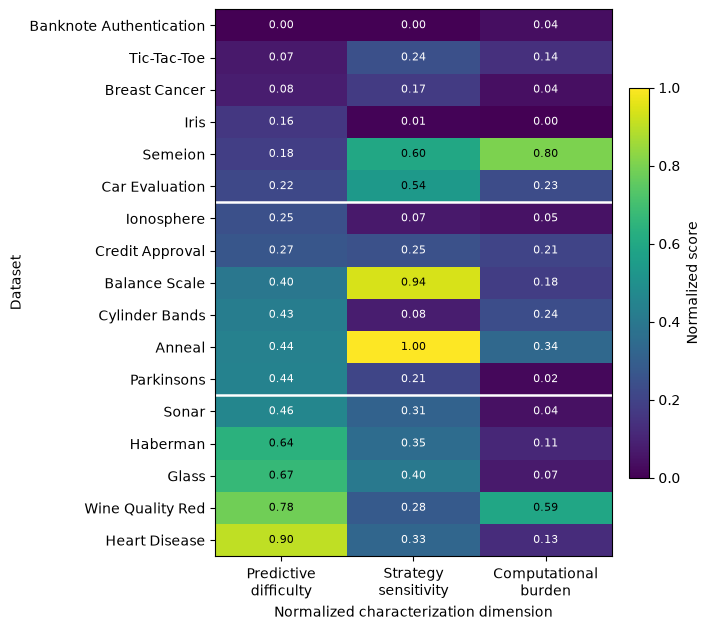

Saved to: C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\results\dataset_statistics\subset_dimension_profiles.pdf


In [28]:
# ============================================================
# Multidimensional dataset-profile heatmap
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


required_columns = [
    "dataset",
    "predictive_difficulty_rank",
    "predictive_difficulty_score",
    "strategy_sensitivity_score",
    "computational_burden_score",
    "predictive_difficulty_label",
]

missing_columns = [
    column
    for column in required_columns
    if column not in dataset_profile_df.columns
]

if missing_columns:
    raise KeyError(
        "The following columns are required to generate the profile figure: "
        f"{missing_columns}"
    )


# Keep only datasets included in the final ranking
profile_plot_df = dataset_profile_df.loc[
    dataset_profile_df["predictive_difficulty_label"].isin(
        ["easy", "intermediate", "hard"]
    ),
    required_columns,
].copy()


# Explicit order of the subsets
label_order = {
    "easy": 0,
    "intermediate": 1,
    "hard": 2,
}

profile_plot_df["label_order"] = (
    profile_plot_df["predictive_difficulty_label"]
    .map(label_order)
)


# Sort first by subset and then by predictive-difficulty score
profile_plot_df = (
    profile_plot_df
    .sort_values(
        [
            "label_order",
            "predictive_difficulty_rank",
        ],
        ascending=[True, True],
    )
    .reset_index(drop=True)
)


# Dataset names formatted for the paper
dataset_display_names = {
    "banknote": "Banknote Authentication",
    "breast_cancer": "Breast Cancer",
    "car": "Car Evaluation",
    "credit_approval": "Credit Approval",
    "cylinder_bands": "Cylinder Bands",
    "heart_disease": "Heart Disease",
    "tic_tac_toe": "Tic-Tac-Toe",
    "wine_red": "Wine Quality Red",
    "balance_scale": "Balance Scale",
    "anneal": "Anneal",
    "glass": "Glass",
    "haberman": "Haberman",
    "ionosphere": "Ionosphere",
    "iris": "Iris",
    "semeion": "Semeion",
    "sonar": "Sonar",
}

profile_plot_df["dataset_display"] = (
    profile_plot_df["dataset"]
    .map(dataset_display_names)
    .fillna(
        profile_plot_df["dataset"]
        .str.replace("_", " ")
        .str.title()
    )
)


dimension_columns = [
    "predictive_difficulty_score",
    "strategy_sensitivity_score",
    "computational_burden_score",
]

dimension_labels = [
    "Predictive\ndifficulty",
    "Strategy\nsensitivity",
    "Computational\nburden",
]

dimension_matrix = profile_plot_df[dimension_columns].to_numpy()


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

figure_height = max(5.5, 0.38 * len(profile_plot_df))

fig, ax = plt.subplots(
    figsize=(7.2, figure_height)
)

heatmap = ax.imshow(
    dimension_matrix,
    aspect="auto",
    vmin=0,
    vmax=1,
)

ax.set_xticks(np.arange(len(dimension_labels)))
ax.set_xticklabels(dimension_labels)

ax.set_yticks(np.arange(len(profile_plot_df)))
ax.set_yticklabels(profile_plot_df["dataset_display"])

ax.set_xlabel("Normalized characterization dimension")
ax.set_ylabel("Dataset")


# Add numerical values
for row_index in range(dimension_matrix.shape[0]):
    for column_index in range(dimension_matrix.shape[1]):
        value = dimension_matrix[row_index, column_index]

        if pd.notna(value):
            ax.text(
                column_index,
                row_index,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value < 0.5 else "black",
            )


# Add horizontal separators between subsets
label_values = profile_plot_df["predictive_difficulty_label"].tolist()

for row_index in range(1, len(label_values)):
    if label_values[row_index] != label_values[row_index - 1]:
        ax.axhline(
            row_index - 0.5,
            linewidth=1.8,
            color="white",
        )


colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.045,
    pad=0.04,
)

colorbar.set_label("Normalized score")

plt.tight_layout()

output_path = output_dir / "subset_dimension_profiles.pdf"

plt.savefig(
    output_path,
    bbox_inches="tight",
)

fig.savefig(output_dir / "subset_dimension_profiles.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"Saved to: {output_path}")


## Paper-aligned exports and final consistency audit
Assertions fail visibly; no manual subset moves are permitted. Reaching the last
cell in a fresh Run All demonstrates sequential execution, including all column
selections. It is not a substitute for rerunning the notebook after future edits.
The optional seed branch requires separate execution when enabled.

In [29]:
exports = {
    'target_audit.csv':target_audit_df, 'dataset_summary.csv':summary_df,
    'baseline_results.csv':baseline_df, 'baseline_cv_performance.csv':baseline_df,
    'baseline_characteristics.csv':baseline_characteristics_df,
    'baseline_dataset_characteristics.csv':baseline_characteristics_df,
    'baseline_cv_audit.csv':cv_audit_df,
    'computational_characteristics.csv':dataset_profile_df[['dataset',
        'baseline_runtime_seconds_mean','mean_tree_nodes','mean_tree_depth','mean_tree_leaves',
        'runtime_burden_score','tree_size_burden_score','computational_burden_score']],
    'dataset_experimental_profile.csv':dataset_profile_df,
    'predictive_difficulty_monotonicity_check.csv':predictive_monotonicity_df,
}
for filename,frame in exports.items():
    frame.to_csv(output_dir / filename,index=False)

checks=[]
def audit_check(name, condition):
    checks.append(dict(check=name, passed=bool(condition)))
    print(('PASS' if condition else 'FAIL')+': '+name)

p=dataset_profile_df
eligible=p.ranking_eligible
ranked_models=baseline_df.loc[baseline_df.dataset.isin(p.loc[eligible,'dataset'])
    & baseline_df.model.isin(NON_DUMMY_BASELINE_MODELS)]
audit_check('Every dataset has explicit target and ID configuration',set(datasets)<=set(TARGET_CONFIG) and set(datasets)<=set(ID_COLUMNS))
audit_check('All ranked datasets satisfy common CV eligibility',p.loc[eligible,'min_class_count'].ge(5).all() and p.loc[eligible,'comparable_cv'].all())
audit_check('All four non-dummy baselines completed',p.loc[eligible,'complete_non_dummy_protocol'].all()
    and ranked_models.groupby('dataset').model.nunique().eq(4).all())
audit_check('Every ranked model has 15 finite CV scores and no error',successful_rows(ranked_models).all())
model_aggregates_ok=True
for _, row in p.loc[eligible].iterrows():
    models=ranked_models.loc[ranked_models.dataset.eq(row.dataset)]
    means=np.array([np.mean(s) for s in models.scores])
    stds=np.array([np.std(s,ddof=1) for s in models.scores])
    model_aggregates_ok &= np.allclose([row.baseline_macro_f1_mean,row.cv_variability,row.strategy_sensitivity],
        [means.mean(),stds.mean(),means.max()-means.min()])
audit_check('F, V and S derive only from four non-dummy score vectors (sample std)',model_aggregates_ok)
audit_check('D_pred equals 0.70*z(E)+0.30*z(V)',np.allclose(p.predictive_difficulty_score,
    .70*p.predictive_error_score+.30*p.cv_variability_score,equal_nan=True))
audit_check('D_comp requires and averages both normalized components',np.allclose(p.computational_burden_score,
    (p.runtime_burden_score+p.tree_size_burden_score)/2,equal_nan=True))
for descriptor in ['strategy_sensitivity','computational_burden_score']:
    perturbed=p.copy(deep=True)
    perturbed[descriptor]=np.arange(len(p))*1000
    labels,ranks=assign_predictive_difficulty_groups(perturbed)
    audit_check(descriptor+' does not affect labels',labels.equals(p.predictive_difficulty_label)
        and ranks.equals(p.predictive_difficulty_rank))
audit_check('Mean F: Easy > Intermediate > Hard',is_monotonic_f1)
article_expected=p.loc[eligible].sort_values('predictive_difficulty_rank').predictive_error_score.round(4).to_numpy()
audit_check('Article table reports z(E), not raw E',np.array_equal(article_ranking_df['z(E_d)'].to_numpy(),article_expected))
audit_check('Downstream tables have required columns',set(['predictive_difficulty_rank','ranking_eligible',
    'ranking_exclusion_reason','cv_variability','possible_issue'])<=set(final_interpretation_df.columns))
audit_check('Canonical results unchanged by supporting analyses',p.equals(canonical_snapshot_df))
audit_check('Noneligible normalized quantities remain NaN',p.loc[~eligible,
    ['predictive_error_score','cv_variability_score','strategy_sensitivity_score',
     'predictive_difficulty_score','runtime_burden_score','tree_size_burden_score','computational_burden_score']].isna().all().all())
audit_check('Canonical alpha=0.70 has no subset changes',weight_sensitivity_summary_df.query('alpha == 0.70').n_subset_changes.eq(0).all())
audit_check('Sequential execution reached final audit',True)
final_consistency_audit_df=pd.DataFrame(checks)
final_consistency_audit_df.to_csv(output_dir / 'final_consistency_audit.csv',index=False)
failed=final_consistency_audit_df.loc[~final_consistency_audit_df.passed,'check'].tolist()
assert not failed, 'Consistency audit failed: '+'; '.join(failed)
print(f'All {len(checks)} consistency checks passed; outputs: {output_dir}')

PASS: Every dataset has explicit target and ID configuration
PASS: All ranked datasets satisfy common CV eligibility
PASS: All four non-dummy baselines completed
PASS: Every ranked model has 15 finite CV scores and no error
PASS: F, V and S derive only from four non-dummy score vectors (sample std)
PASS: D_pred equals 0.70*z(E)+0.30*z(V)
PASS: D_comp requires and averages both normalized components
PASS: strategy_sensitivity does not affect labels
PASS: computational_burden_score does not affect labels
PASS: Mean F: Easy > Intermediate > Hard
PASS: Article table reports z(E), not raw E
PASS: Downstream tables have required columns
PASS: Canonical results unchanged by supporting analyses
PASS: Noneligible normalized quantities remain NaN
PASS: Canonical alpha=0.70 has no subset changes
PASS: Sequential execution reached final audit
All 16 consistency checks passed; outputs: C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\results\dataset_statistics
